# Predviđanje revizorskog mišljenja za javna preduzeća u FBiH
# Audit opinion prediction for public enterprises in FBiH

Ulaz: 23 bilansne pozicije (t i t-1) iz kolona **prije** „Mišljenje“. Cilj: `cilj_binarno` (1 = pozitivno + s rezervom, 0 = negativno + suzdržavanje).
Kolone nakon „Osnov za mišljenje“ (Beneish omjeri, M-score, 0/1 oznake) **nisu** uključene; omjeri koji se koriste u poređenju skupova atributa izračunavaju se u ovom notebooku isključivo iz istih 23 sirovih pozicija.

## Projektni okvir i pokrivenost zahtjeva - study framework

**Predmet:** klasifikacija finansijskih izvještaja javnih preduzeća u FBiH; revizorsko mišljenje je proxy za tačnost/kvalitet izvještaja.

**Posebni ciljevi:** (1) uporediti algoritme (J48, k-NN/IBk, MLP, BayesNet + dodatni), (2) utvrditi koji skup atributa daje najbolju prediktivnu moć, (3) ocijeniti modele metrikama accuracy, precision, recall, F-measure, ROC i konfuzionom matricom.

**Hipoteze (operacionalizacija):**
- **H1:** moguće je klasifikovati izvještaje uz zadovoljavajuću tačnost. Prihvata se ako najbolji model u grupnoj CV ima AUC i tačnost značajno iznad osnovnog nivoa (korigovani t-test, p < 0,05).
- **H2:** tačnost zavisi od algoritma i skupa atributa. Prihvata se ako Friedmanov test pokaže značajnu razliku među algoritmima, odnosno među skupovima atributa (p < 0,05).

**Ciljna varijabla (eksplicitno):** binarno, 1 = pozitivno + s rezervom (201), 0 = negativno + suzdržavanje od mišljenja (111). Razlog: četiri klase nisu izvodljive (suzdržavanje ima 6 primjera). Uputama predviđena varijanta „pozitivno vs ostalo“ (37 : 275) i troklasna varijanta provjeravaju se u analizi osjetljivosti.

**Validacija:** 10-fold stratifikovana CV (obavezno), grupna CV po preduzećima (bez curenja iste firme u trening i test), te vremenski testovi (jedan rez i klizna validacija).

| Zahtjev iz uputa | Gdje u notebooku |
|---|---|
| Priprema podataka, nedostajuće vrijednosti, klasa, eksport .csv/.arff | čišćenje, ciljna varijabla, ćelija za ARFF eksport |
| Selekcija atributa (InfoGain, CFS) uz rang | sekcija „Selekcija atributa“ |
| Koji skup atributa je najbolji (H2) | sekcija „Poređenje skupova atributa“ |
| J48, IBk, MLP, BayesNet | sekcija „Četiri algoritma iz uputa (WEKA-slične verzije)“ |
| 10-fold CV | sekcije 10-fold CV i WEKA-slične verzije |
| Metrike, ROC, konfuziona matrica, izbor najboljeg modela | sekcija „Izbor najboljeg modela“ |
| Statistička provjera H1 i H2 | sekcija „Statistički testovi“ |
| Rangiranje preduzeća po riziku (praktični doprinos) | sekcije „Rangiranje rizika“ i „Klizna vremenska validacija“ |

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, pointbiserialr, chi2_contingency, skew, kurtosis

from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, precision_recall_curve
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, matthews_corrcoef,
                             average_precision_score, ConfusionMatrixDisplay)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost nije instaliran (pip install xgboost) - preskače se.")

sns.set_theme(style='whitegrid')
RS = 42

## Dataset loading - učitavanje dataseta

In [2]:
import os
putanja = 'data/dataset_revizija.csv' if os.path.exists('data/dataset_revizija.csv') else 'dataset_revizija.csv'
df = pd.read_csv(putanja)

## Display info about data and first five rows - prikaz informacija o datasetu i prvih 5 redova

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_preduzeca            312 non-null    object 
 1   Sektor                  312 non-null    object 
 2   Godina_izvjestaja       312 non-null    int64  
 3   potrazivanja_kupci_t    312 non-null    int64  
 4   prihod_prodaja_t        312 non-null    int64  
 5   potrazivanja_kupci_t1   312 non-null    int64  
 6   prihod_prodaja_t1       312 non-null    int64  
 7   poslovni_rashodi_t1     312 non-null    int64  
 8   poslovni_rashodi_t      312 non-null    int64  
 9   obrtna_imovina_t        312 non-null    int64  
 10  nekretnine_oprema_t     312 non-null    int64  
 11  kratk_fin_plasmani_t    312 non-null    int64  
 12  poslovna_imovina_t      312 non-null    int64  
 13  obrtna_imovina_t1       312 non-null    int64  
 14  nekretnine_oprema_t1    312 non-null    in

In [4]:
df.head()

,ID_preduzeca,Sektor,Godina_izvjestaja,potrazivanja_kupci_t,prihod_prodaja_t,potrazivanja_kupci_t1,prihod_prodaja_t1,poslovni_rashodi_t1,poslovni_rashodi_t,obrtna_imovina_t,...,admin_rashodi_t,admin_rashodi_t1,kratk_obaveze_t,dugor_obaveze_t,kratk_obaveze_t1,dugor_obaveze_t1,novcani_tok_poslovni_t,misljenje,cilj_binarno,cilj_3klase
0,P001,Saobraćaj i infrastruktura,2018,1569973,34564122,2616396,36116977,45061690,43346981,13818573,...,29718683,31568284,225902690,0,215699458,0,-13704996.0,Negativno mišljenje,0,2
1,P002,Energetika i rudarstvo,2018,1737302,98336465,7469401,104563987,115511122,118848833,29156474,...,63494948,65316748,231694960,50518921,215908909,51300250,-22088244.0,Negativno mišljenje,0,2
2,P002,Energetika i rudarstvo,2018,2968910,67346322,3082738,80447397,77801891,79173988,9709508,...,46690135,47987133,108713252,10029776,103778117,10018683,8137240.0,Negativno mišljenje,0,2
3,P002,Energetika i rudarstvo,2018,1226574,12202060,1131792,12645798,13914208,14072426,3261233,...,9513606,9508934,39090700,471429,34384033,550000,3729683.0,Negativno mišljenje,0,2
4,P003,Komunalne djelatnosti,2018,721617,2064254,719155,2294813,2291551,2119059,1536103,...,1098925,1101113,1094978,0,815974,0,354760.0,Mišljenje s rezervom,1,1


## Displaying the number of missing values - broj nedostajućih vrijednosti

In [5]:
print(df.isnull().sum()[df.isnull().sum() > 0])

novcani_tok_poslovni_t    2
dtype: int64


Jedine nedostajuće vrijednosti su 2 u `novcani_tok_poslovni_t`; popunjavaju se imputacijom. Godina je kompletna: za 4 izvještaja čiji naziv ne sadrži godinu postavljena je vrijednost 2020, pa nijedan red nije izgubljen.

The only missing values are 2 in operating cash flow (imputed). Report year is complete: 4 reports without a year in the name were set to 2020, so no rows are lost.

## Defining variable groups - definisanje grupa varijabli

In [6]:
meta_kolone = ['ID_preduzeca', 'Sektor', 'Godina_izvjestaja']
ciljne_kolone = ['misljenje', 'cilj_binarno', 'cilj_3klase']
numericke = [c for c in df.columns if c not in meta_kolone + ciljne_kolone]
print(len(numericke), "ulaznih numeričkih varijabli:")
print(numericke)

23 ulaznih numeričkih varijabli:
['potrazivanja_kupci_t', 'prihod_prodaja_t', 'potrazivanja_kupci_t1', 'prihod_prodaja_t1', 'poslovni_rashodi_t1', 'poslovni_rashodi_t', 'obrtna_imovina_t', 'nekretnine_oprema_t', 'kratk_fin_plasmani_t', 'poslovna_imovina_t', 'obrtna_imovina_t1', 'nekretnine_oprema_t1', 'kratk_fin_plasmani_t1', 'poslovna_imovina_t1', 'amortizacija_t1', 'amortizacija_t', 'admin_rashodi_t', 'admin_rashodi_t1', 'kratk_obaveze_t', 'dugor_obaveze_t', 'kratk_obaveze_t1', 'dugor_obaveze_t1', 'novcani_tok_poslovni_t']


`ID_preduzeca`, `Sektor` i `Godina_izvjestaja` **nisu** ulazne varijable osnovnog modela: ID služi samo za validaciju po preduzećima, godina za vremenski test, a sektor se testira kao dodatak (vidi kasnije).

## Data cleaning - čišćenje podataka
### Impossible zero values treated as missing / Nemoguće nule tretirane kao nedostajuće vrijednosti
Preduzeće ne može imati nekretnine/opremu ili amortizaciju jednaku 0 u obje godine istovremeno dok drugu poziciju ima; takvi unosi se tretiraju kao greška i postavljaju na NaN (popunjava ih imputer unutar pipeline-a).

In [7]:
par = [('nekretnine_oprema_t', 'nekretnine_oprema_t1'), ('amortizacija_t', 'amortizacija_t1')]
for a, b in par:
    maska = (df[a] == 0) & (df[b] == 0)
    print(f"{a}/{b}: sumnjivih redova = {int(maska.sum())}", df.loc[maska, 'ID_preduzeca'].tolist())
    df.loc[maska, [a, b]] = np.nan
print("\nNedostajuće vrijednosti nakon čišćenja:")
print(df[numericke].isnull().sum()[df[numericke].isnull().sum() > 0])
print("Broj redova:", len(df))

nekretnine_oprema_t/nekretnine_oprema_t1: sumnjivih redova = 1 ['P045']
amortizacija_t/amortizacija_t1: sumnjivih redova = 1 ['P019']

Nedostajuće vrijednosti nakon čišćenja:
nekretnine_oprema_t       1
nekretnine_oprema_t1      1
amortizacija_t1           1
amortizacija_t            1
novcani_tok_poslovni_t    2
dtype: int64
Broj redova: 312


## Target variable distribution - raspodjela ciljne varijable

In [8]:
print(df['misljenje'].value_counts())
print()
print(df['cilj_binarno'].value_counts())
print(df['cilj_binarno'].value_counts(normalize=True).round(3))

misljenje
Mišljenje s rezervom         164
Negativno mišljenje          105
Pozitivno mišljenje           37
Suzdržavanje od mišljenja      6
Name: count, dtype: int64

cilj_binarno
1    201
0    111
Name: count, dtype: int64
cilj_binarno
1    0.644
0    0.356
Name: proportion, dtype: float64


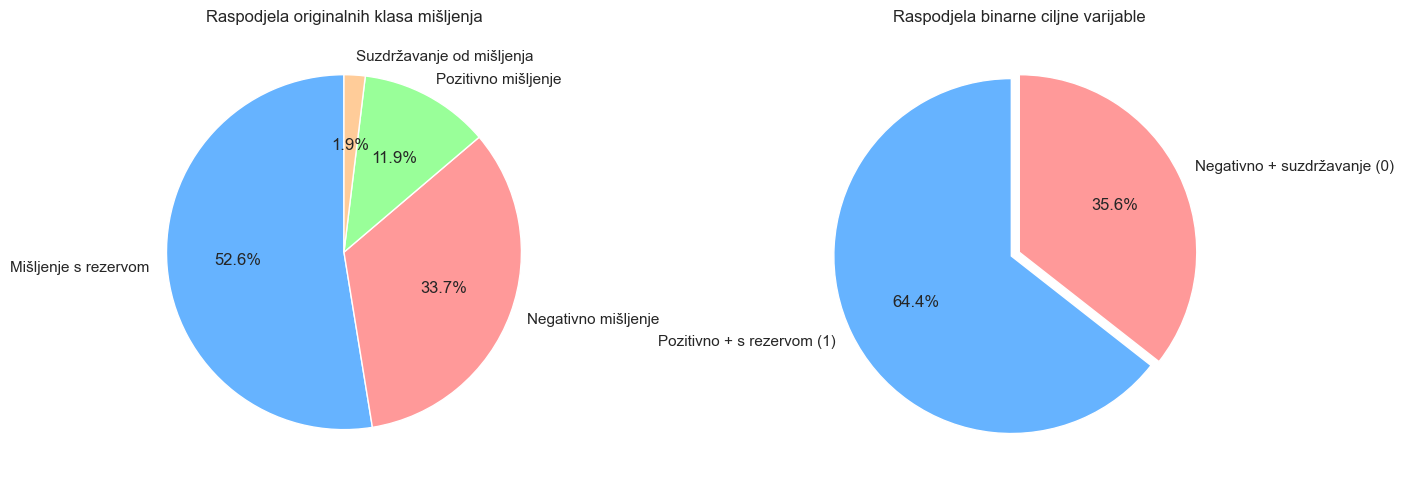

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['misljenje'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, ax=axes[0],
                                    colors=['#66b3ff', '#ff9999', '#99ff99', '#ffcc99'])
axes[0].set_title('Raspodjela originalnih klasa mišljenja')
axes[0].set_ylabel('')

df['cilj_binarno'].map({1: 'Pozitivno + s rezervom (1)', 0: 'Negativno + suzdržavanje (0)'}) \
    .value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, explode=(0.05, 0), ax=axes[1],
                         colors=['#66b3ff', '#ff9999'])
axes[1].set_title('Raspodjela binarne ciljne varijable')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

Binarna raspodjela (oko 64% / 36%) dovoljno je uravnotežena za klasifikaciju. Originalne 4 klase nisu pogodne za modeliranje jer klasa *suzdržavanje* ima samo 6 primjera.

The binary split (~64/36) is balanced enough for classification. The original four classes are not suitable because 'disclaimer of opinion' has only 6 examples.

## Calculating skewness and kurtosis - asimetrija i zaobljenost

In [10]:
skew_kurt = pd.DataFrame({
    'skewness': [skew(df[v].dropna()) for v in numericke],
    'kurtosis': [kurtosis(df[v].dropna(), fisher=True) for v in numericke]
}, index=numericke).round(3)
print(skew_kurt)

                        skewness  kurtosis
potrazivanja_kupci_t       4.480    30.907
prihod_prodaja_t           3.755    15.193
potrazivanja_kupci_t1      4.798    32.903
prihod_prodaja_t1          3.518    12.940
poslovni_rashodi_t1        3.774    15.752
poslovni_rashodi_t         3.989    17.883
obrtna_imovina_t           4.210    21.367
nekretnine_oprema_t        2.856     8.382
kratk_fin_plasmani_t       5.690    32.400
poslovna_imovina_t         2.367     5.249
obrtna_imovina_t1          4.217    21.200
nekretnine_oprema_t1       2.748     7.242
kratk_fin_plasmani_t1      6.030    37.099
poslovna_imovina_t1        2.349     5.164
amortizacija_t1            3.521    13.161
amortizacija_t             3.216     9.988
admin_rashodi_t            7.688    71.109
admin_rashodi_t1           7.328    65.338
kratk_obaveze_t            3.674    15.987
dugor_obaveze_t            8.525    85.455
kratk_obaveze_t1           3.742    16.361
dugor_obaveze_t1           7.529    65.258
novcani_tok

Sve finansijske pozicije imaju izrazito desnu asimetriju (veliki broj malih i nekoliko vrlo velikih preduzeća), pa se za modele osjetljive na skalu (LR, SVM, k-NN, MLP) primjenjuje signed log transformacija unutar pipeline-a.

All financial items are strongly right-skewed, so a signed-log transform is applied inside the pipeline for scale-sensitive models.

## Missing values - nedostajuće vrijednosti
Nedostajuće vrijednosti se **ne popunjavaju u dataframe-u**, nego unutar svakog `Pipeline`-a (`SimpleImputer(median)`; parametri se uče samo na trening dijelu, bez curenja podataka). Medijan je opravdan jer su sve pozicije jako asimetrične (|skewness| > 1, vidi gore). Deskriptivna statistika i korelacije automatski ignorišu NaN (po parovima).

In [11]:
nedostaje = df[numericke].isnull().sum()
nedostaje = nedostaje[nedostaje > 0]
print("Nedostajuće vrijednosti po kolonama:")
print(nedostaje)
print("\nUkupno:", int(nedostaje.sum()), "ćelija od", df[numericke].size, f"({nedostaje.sum() / df[numericke].size:.4%})")
print("Redova s barem jednom nedostajućom vrijednošću:", int(df[numericke].isnull().any(axis=1).sum()))
print("Kolone s |skew| <= 1 (kandidati za mean umjesto median):", [v for v in numericke if abs(skew(df[v].dropna())) <= 1])

Nedostajuće vrijednosti po kolonama:
nekretnine_oprema_t       1
nekretnine_oprema_t1      1
amortizacija_t1           1
amortizacija_t            1
novcani_tok_poslovni_t    2
dtype: int64

Ukupno: 6 ćelija od 7176 (0.0836%)
Redova s barem jednom nedostajućom vrijednošću: 4
Kolone s |skew| <= 1 (kandidati za mean umjesto median): []


## Descriptive statistic - deskriptivna statistika

In [12]:
pd.options.display.float_format = '{:,.2f}'.format
df[numericke].describe().T

,count,mean,std,min,25%,50%,75%,max
potrazivanja_kupci_t,312.00,"15,921,516.25","34,062,419.47",0.00,"742,518.75","2,147,698.50","13,085,166.00","347,532,514.00"
prihod_prodaja_t,312.00,"89,275,579.44","196,669,869.07","195,826.00","4,704,766.75","16,655,526.50","69,443,463.50","1,274,763,145.00"
potrazivanja_kupci_t1,312.00,"16,526,547.48","37,694,288.07",0.00,"674,705.25","2,076,993.00","13,875,010.25","382,234,948.00"
prihod_prodaja_t1,312.00,"87,885,910.24","189,537,682.61","68,460.00","4,578,149.00","16,953,060.00","67,260,480.00","1,139,628,124.00"
poslovni_rashodi_t1,312.00,"82,879,751.20","175,596,160.54","427,014.00","4,910,293.50","19,869,675.00","66,718,241.75","1,217,523,074.00"
poslovni_rashodi_t,312.00,"84,890,682.57","183,077,229.08","445,178.00","4,998,940.50","19,720,154.00","66,233,766.75","1,306,910,856.00"
obrtna_imovina_t,312.00,"52,037,254.14","116,131,267.81","152,624.00","2,406,594.25","10,038,017.00","50,979,465.75","995,833,019.00"
nekretnine_oprema_t,311.00,"303,494,757.69","685,838,291.84","33,879.00","5,271,759.00","16,680,198.00","103,872,619.00","4,352,208,031.00"
kratk_fin_plasmani_t,312.00,"6,469,545.00","32,499,094.19",0.00,0.00,0.00,0.00,"240,666,387.00"
poslovna_imovina_t,312.00,"491,548,163.84","924,712,253.92","455,151.00","10,434,908.50","46,458,529.50","370,311,887.25","4,655,590,916.00"


In [13]:
# Deskriptivna statistika po klasama ciljne varijable (medijan, jer su podaci asimetrični)
df.groupby('cilj_binarno')[numericke].median().T.rename(columns={0: 'Negativno/suzdržavanje (0)', 1: 'Pozitivno/s rezervom (1)'})

cilj_binarno,Negativno/suzdržavanje (0),Pozitivno/s rezervom (1)
potrazivanja_kupci_t,"2,909,334.00","1,960,717.00"
prihod_prodaja_t,"13,099,028.00","22,680,756.00"
potrazivanja_kupci_t1,"2,674,040.00","1,881,653.00"
prihod_prodaja_t1,"12,667,595.00","22,680,756.00"
poslovni_rashodi_t1,"15,043,478.00","22,662,751.00"
poslovni_rashodi_t,"16,253,120.00","24,900,599.00"
obrtna_imovina_t,"9,634,049.00","11,212,186.00"
nekretnine_oprema_t,"20,518,263.00","13,974,539.00"
kratk_fin_plasmani_t,0.00,0.00
poslovna_imovina_t,"47,965,587.00","39,016,139.00"


## Histograms for numeric variables - histogrami (log skala)

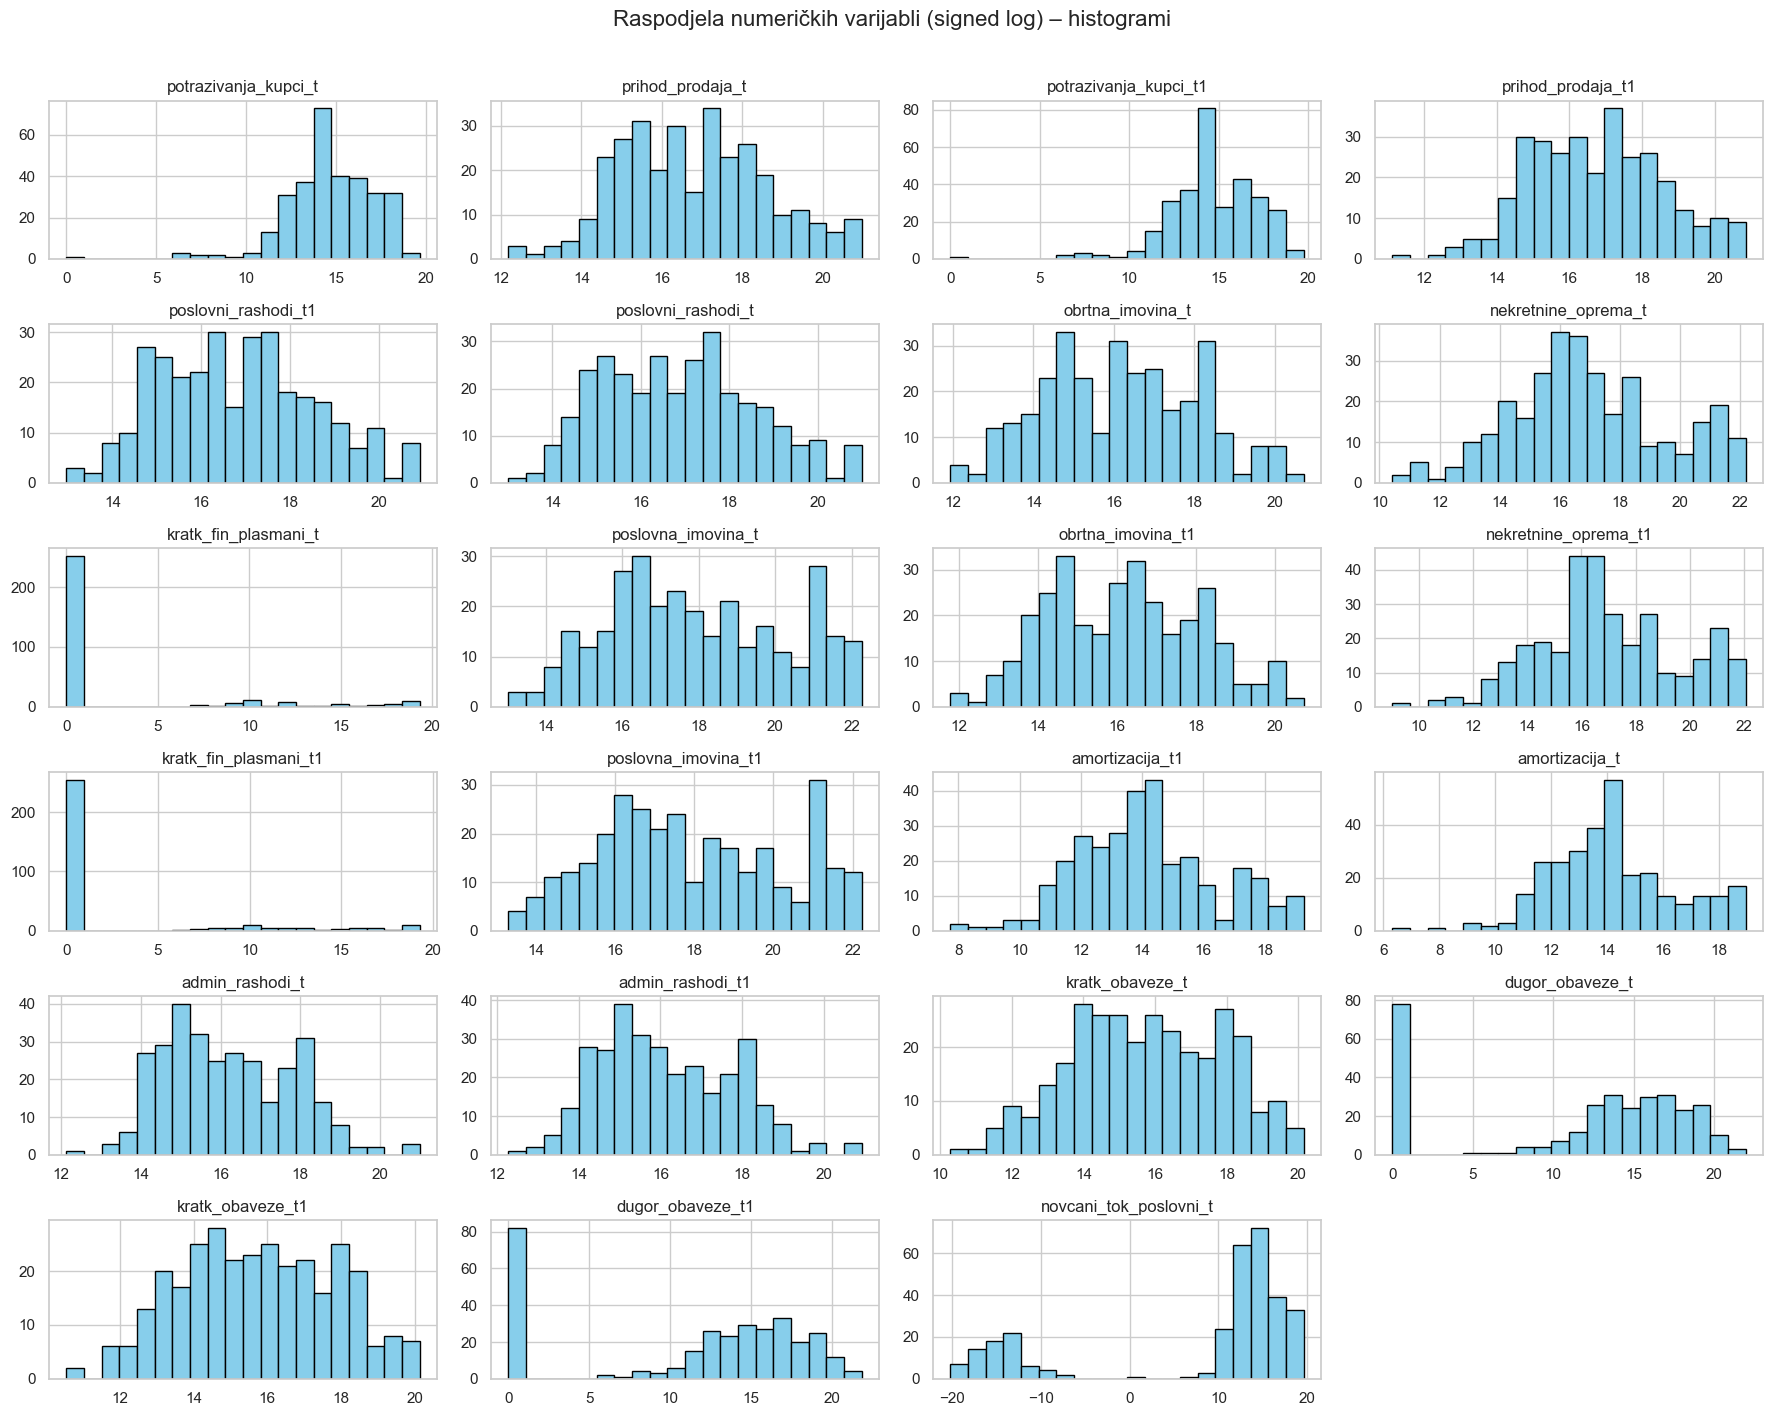

In [14]:
def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

df_log = df[numericke].apply(slog)

df_log.hist(bins=20, figsize=(18, 14), layout=(6, 4), color='skyblue', edgecolor='black')
plt.suptitle('Raspodjela numeričkih varijabli (signed log) – histogrami', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

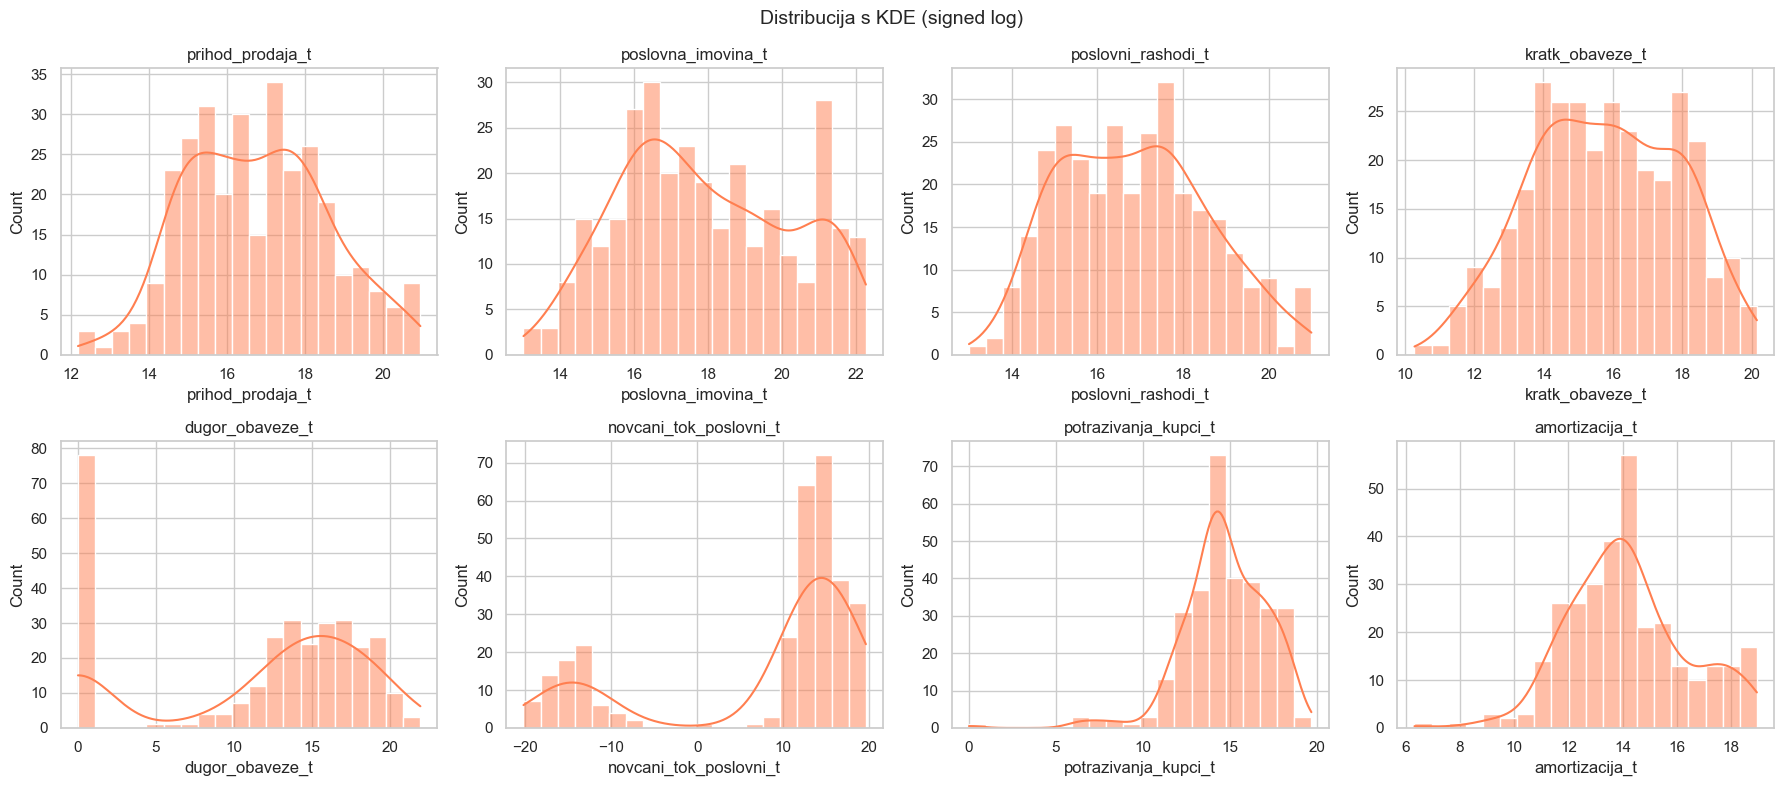

In [15]:
kljucne = ['prihod_prodaja_t', 'poslovna_imovina_t', 'poslovni_rashodi_t', 'kratk_obaveze_t',
           'dugor_obaveze_t', 'novcani_tok_poslovni_t', 'potrazivanja_kupci_t', 'amortizacija_t']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, var in enumerate(kljucne):
    sns.histplot(df_log[var], kde=True, bins=20, ax=axes[i], color='coral')
    axes[i].set_title(var)
plt.suptitle('Distribucija s KDE (signed log)', fontsize=14)
plt.tight_layout()
plt.show()

## Boxplots by opinion class - boxplot po klasi mišljenja

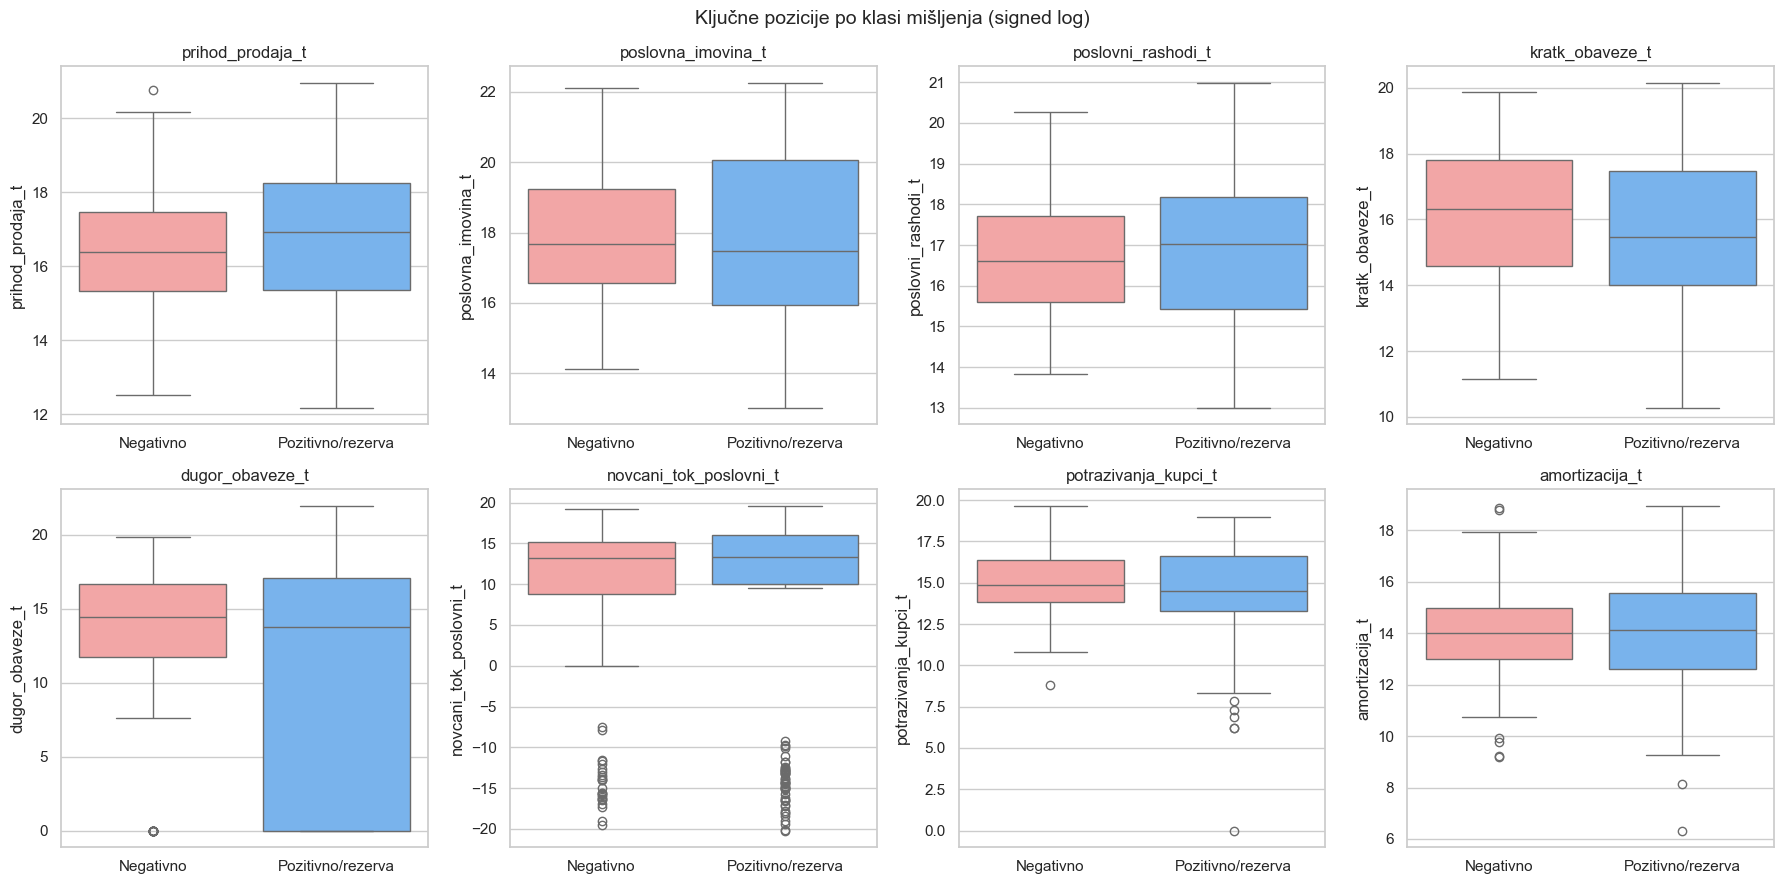

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for i, var in enumerate(kljucne):
    sns.boxplot(x=df['cilj_binarno'].map({0: 'Negativno', 1: 'Pozitivno/rezerva'}), y=df_log[var],
                ax=axes[i], palette=['#ff9999', '#66b3ff'])
    axes[i].set_title(var)
    axes[i].set_xlabel('')
plt.suptitle('Ključne pozicije po klasi mišljenja (signed log)', fontsize=14)
plt.tight_layout()
plt.show()

## Outliers - IQR analiza (bez uklanjanja)

In [17]:
q1 = df[numericke].quantile(0.25)
q3 = df[numericke].quantile(0.75)
iqr = q3 - q1
outlieri = ((df[numericke] < (q1 - 1.5 * iqr)) | (df[numericke] > (q3 + 1.5 * iqr))).sum().sort_values(ascending=False)
print(outlieri)

novcani_tok_poslovni_t    75
nekretnine_oprema_t       61
nekretnine_oprema_t1      61
poslovna_imovina_t        61
dugor_obaveze_t           60
dugor_obaveze_t1          60
poslovna_imovina_t1       60
kratk_fin_plasmani_t      60
kratk_fin_plasmani_t1     58
amortizacija_t            53
amortizacija_t1           53
potrazivanja_kupci_t      45
prihod_prodaja_t          42
poslovni_rashodi_t1       41
poslovni_rashodi_t        41
potrazivanja_kupci_t1     39
prihod_prodaja_t1         39
obrtna_imovina_t1         36
kratk_obaveze_t           34
kratk_obaveze_t1          33
obrtna_imovina_t          29
admin_rashodi_t           29
admin_rashodi_t1          28
dtype: int64


## Year and sector analysis - analiza po godinama i sektorima

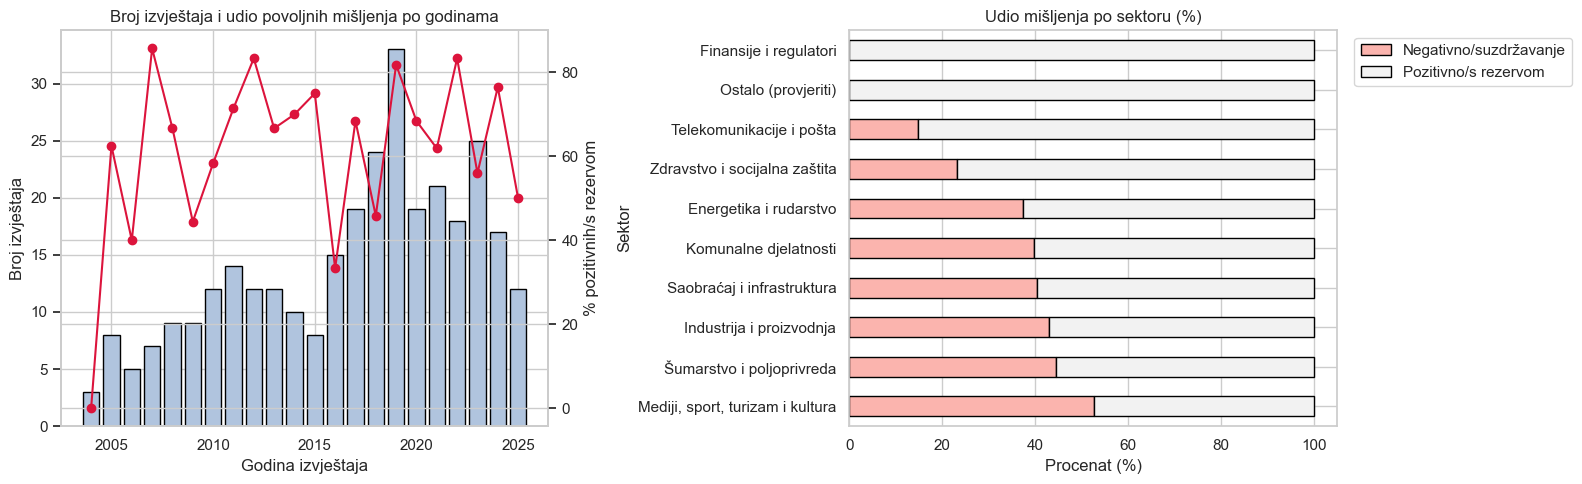

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

po_godini = df.dropna(subset=['Godina_izvjestaja']).groupby('Godina_izvjestaja')['cilj_binarno'].agg(['count', 'mean'])
axes[0].bar(po_godini.index, po_godini['count'], color='lightsteelblue', edgecolor='black')
axes[0].set_ylabel('Broj izvještaja')
axes[0].set_xlabel('Godina izvještaja')
ax2 = axes[0].twinx()
ax2.plot(po_godini.index, po_godini['mean'] * 100, color='crimson', marker='o')
ax2.set_ylabel('% pozitivnih/s rezervom')
axes[0].set_title('Broj izvještaja i udio povoljnih mišljenja po godinama')

crosstab = pd.crosstab(df['Sektor'], df['cilj_binarno'], normalize='index') * 100
crosstab.columns = ['Negativno/suzdržavanje', 'Pozitivno/s rezervom']
crosstab.sort_values('Pozitivno/s rezervom').plot(kind='barh', stacked=True, ax=axes[1], colormap='Pastel1', edgecolor='black')
axes[1].set_title('Udio mišljenja po sektoru (%)')
axes[1].set_xlabel('Procenat (%)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [19]:
print(df['Sektor'].value_counts())

Sektor
Komunalne djelatnosti               63
Saobraćaj i infrastruktura          62
Energetika i rudarstvo              59
Telekomunikacije i pošta            34
Šumarstvo i poljoprivreda           27
Zdravstvo i socijalna zaštita       26
Mediji, sport, turizam i kultura    19
Industrija i proizvodnja            14
Finansije i regulatori               7
Ostalo (provjeriti)                  1
Name: count, dtype: int64


In [20]:
contingency = pd.crosstab(df['Sektor'], df['cilj_binarno'], rownames=['Sektor'], colnames=['Povoljno mišljenje'])
print(contingency)
chi2, p_chi, dof, expected = chi2_contingency(contingency)
print(f"\nChi-square test: chi2 = {chi2:.4f}, dof = {dof}, p = {p_chi:.4f}")
print("Postoji značajna povezanost sektora i mišljenja (p<0.05)" if p_chi < 0.05 else "Nema značajne povezanosti")
print("Napomena: neka očekivana brojnost < 5 (mali sektori), rezultat tumačiti oprezno:",
      int((expected < 5).sum()), "ćelija")

Povoljno mišljenje                 0   1
Sektor                                  
Energetika i rudarstvo            22  37
Finansije i regulatori             0   7
Industrija i proizvodnja           6   8
Komunalne djelatnosti             25  38
Mediji, sport, turizam i kultura  10   9
Ostalo (provjeriti)                0   1
Saobraćaj i infrastruktura        25  37
Telekomunikacije i pošta           5  29
Zdravstvo i socijalna zaštita      6  20
Šumarstvo i poljoprivreda         12  15

Chi-square test: chi2 = 17.4614, dof = 9, p = 0.0420
Postoji značajna povezanost sektora i mišljenja (p<0.05)
Napomena: neka očekivana brojnost < 5 (mali sektori), rezultat tumačiti oprezno: 5 ćelija


Sektor je slabo, ali statistički značajno povezan s mišljenjem (telekomunikacije i pošta te zdravstvo imaju najveći udio povoljnih mišljenja). Sektor je dodjeljen automatski iz naziva preduzeća i treba ga ručno provjeriti.

Sector is weakly but significantly associated with the opinion. It was assigned automatically from the enterprise name and should be verified manually.

## Correlation matrix - korelacijska matrica

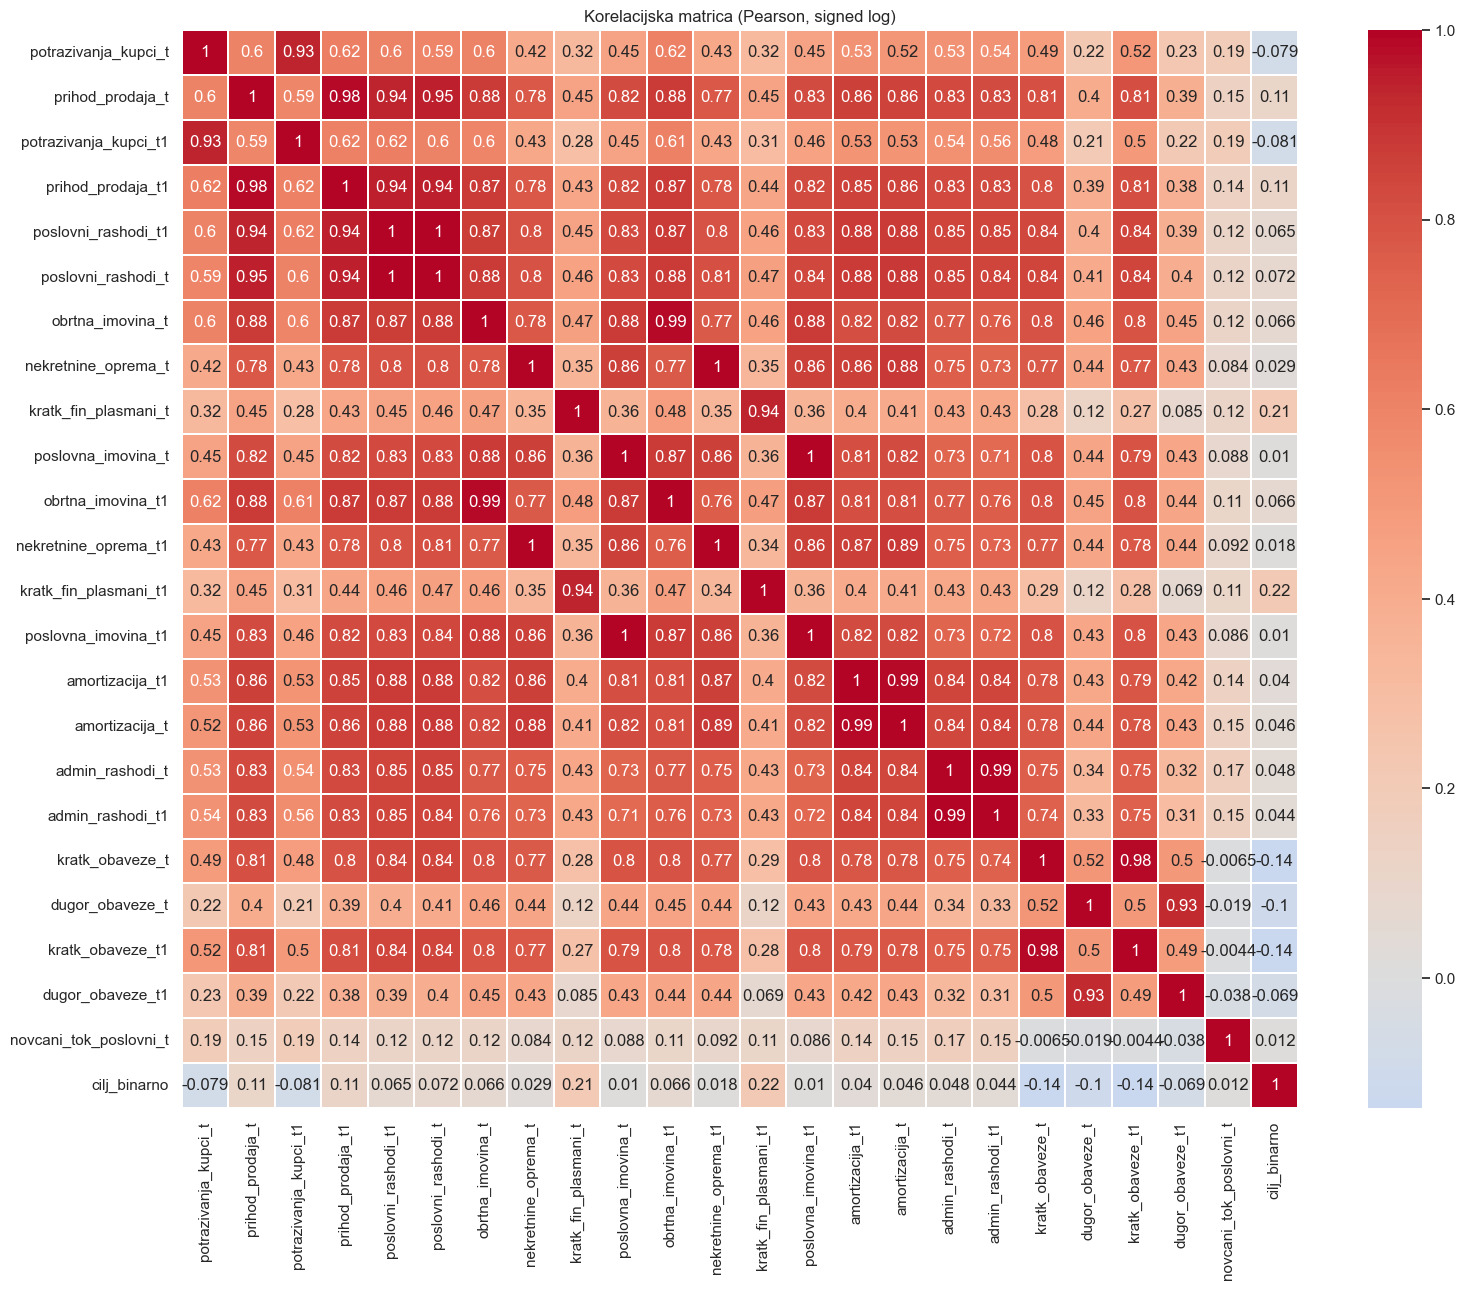

In [21]:
df_corr = df[numericke + ['cilj_binarno']].copy()
df_corr[numericke] = df_corr[numericke].apply(slog)   # signed log zbog asimetrije
correlation_matrix = df_corr.corr(method='pearson')

plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Korelacijska matrica (Pearson, signed log)')
plt.show()

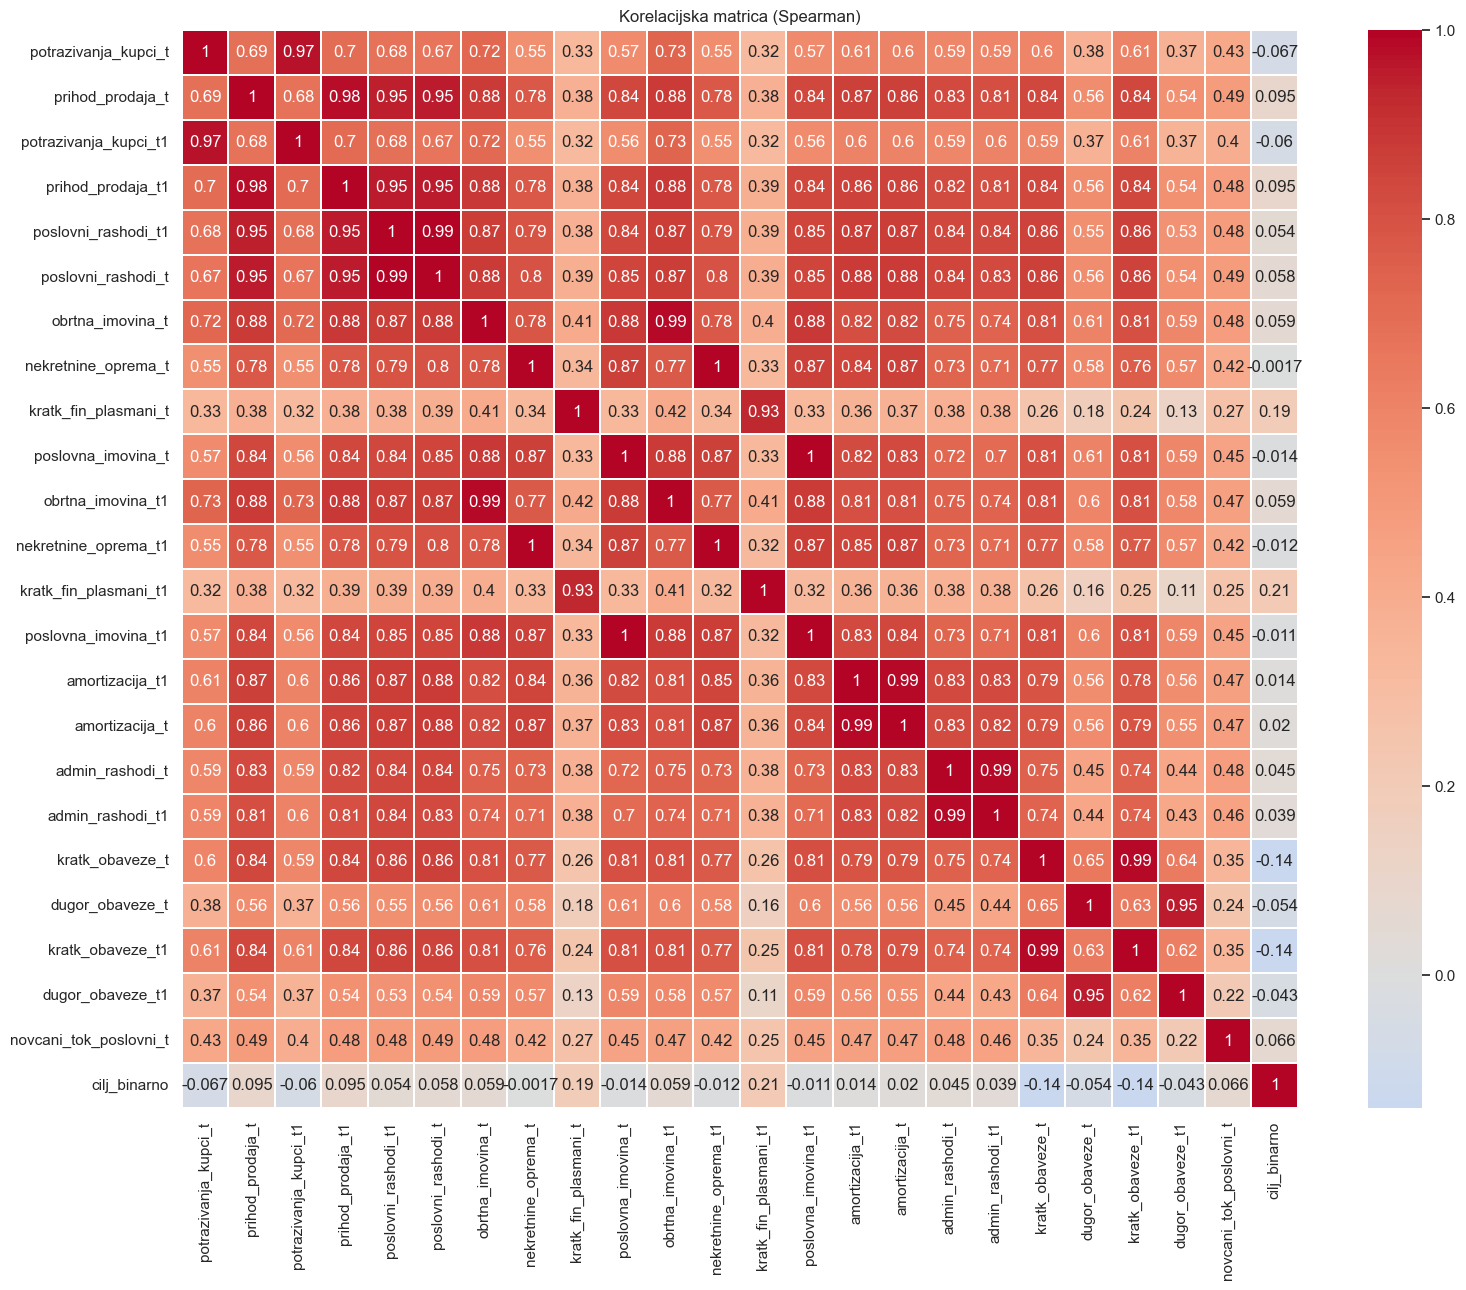

In [22]:
# Spearman (robustan na asimetriju i outliere)
spearman_matrix = df[numericke + ['cilj_binarno']].corr(method='spearman')
plt.figure(figsize=(18, 14))
sns.heatmap(spearman_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.3)
plt.title('Korelacijska matrica (Spearman)')
plt.show()

## Correlation with p-values - korelacije s p-vrijednostima

In [23]:
def korelacija_sa_p_vrijednostima(data, varijable=None):
    d = data[varijable].dropna() if varijable is not None else data.dropna()
    n = d.shape[1]
    corr = np.zeros((n, n)); pval = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            corr[i, j], pval[i, j] = pearsonr(d.iloc[:, i], d.iloc[:, j])
    return pd.DataFrame(corr, index=d.columns, columns=d.columns), pd.DataFrame(pval, index=d.columns, columns=d.columns)

korelacije, p_vrijednosti = korelacija_sa_p_vrijednostima(df_corr)

print("ZNAČAJNE KORELACIJE S CILJNOM VARIJABLOM (p < 0.05)")
print("=" * 70)
ciljne = pd.DataFrame({'r': korelacije['cilj_binarno'], 'p': p_vrijednosti['cilj_binarno']}).drop('cilj_binarno')
ciljne['znacajnost'] = ciljne['p'].apply(lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '')
print(ciljne.sort_values('r', key=abs, ascending=False).round(4))

ZNAČAJNE KORELACIJE S CILJNOM VARIJABLOM (p < 0.05)
                           r    p znacajnost
kratk_fin_plasmani_t    0.22 0.00        ***
kratk_fin_plasmani_t1   0.21 0.00        ***
kratk_obaveze_t        -0.14 0.01          *
kratk_obaveze_t1       -0.14 0.01          *
prihod_prodaja_t1       0.11 0.05           
prihod_prodaja_t        0.10 0.07           
dugor_obaveze_t        -0.10 0.08           
potrazivanja_kupci_t1  -0.09 0.14           
potrazivanja_kupci_t   -0.08 0.15           
dugor_obaveze_t1       -0.07 0.23           
poslovni_rashodi_t      0.07 0.25           
obrtna_imovina_t        0.06 0.26           
obrtna_imovina_t1       0.06 0.26           
poslovni_rashodi_t1     0.06 0.31           
admin_rashodi_t         0.04 0.46           
amortizacija_t          0.04 0.47           
admin_rashodi_t1        0.04 0.51           
amortizacija_t1         0.03 0.57           
nekretnine_oprema_t     0.02 0.74           
novcani_tok_poslovni_t  0.01 0.81           
nek

                           r    p
kratk_fin_plasmani_t1   0.22 0.00
kratk_fin_plasmani_t    0.21 0.00
kratk_obaveze_t1       -0.14 0.02
kratk_obaveze_t        -0.14 0.02
prihod_prodaja_t1       0.11 0.04
prihod_prodaja_t        0.11 0.06
dugor_obaveze_t        -0.10 0.07
potrazivanja_kupci_t1  -0.08 0.15
potrazivanja_kupci_t   -0.08 0.16
poslovni_rashodi_t      0.07 0.20
dugor_obaveze_t1       -0.07 0.22
obrtna_imovina_t1       0.07 0.25
obrtna_imovina_t        0.07 0.25
poslovni_rashodi_t1     0.07 0.25
admin_rashodi_t         0.05 0.40
amortizacija_t          0.05 0.41
admin_rashodi_t1        0.04 0.43
amortizacija_t1         0.04 0.48
nekretnine_oprema_t     0.03 0.61
nekretnine_oprema_t1    0.02 0.76
novcani_tok_poslovni_t  0.01 0.84
poslovna_imovina_t      0.01 0.86
poslovna_imovina_t1     0.01 0.86


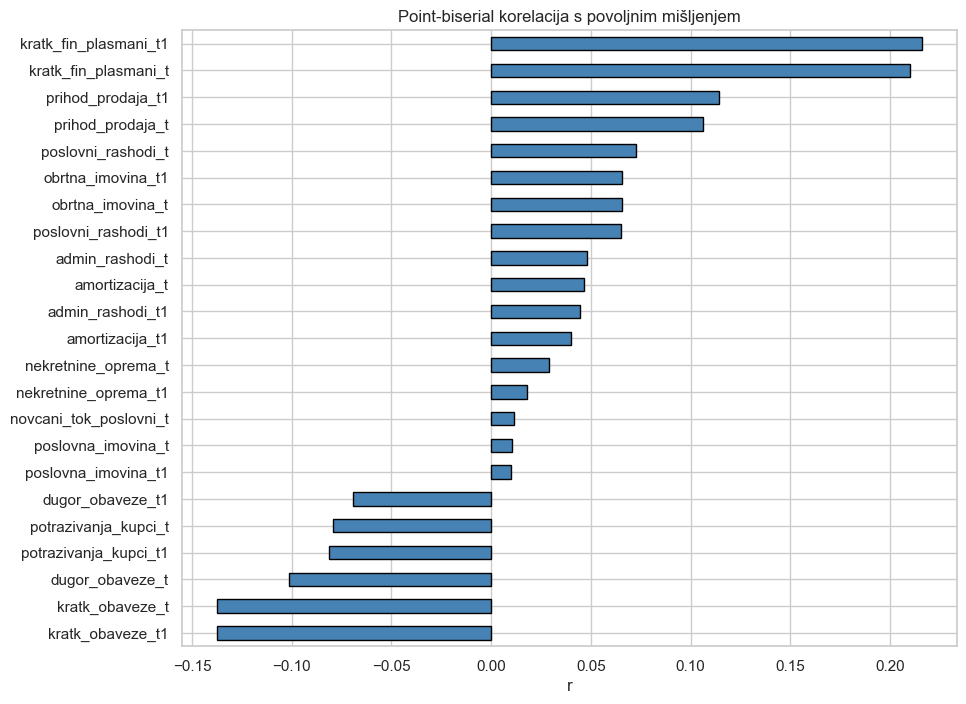

In [24]:
# Point-biserial korelacija (binarna cilj varijabla vs neprekidne varijable), na signed log vrijednostima
pb = {v: pointbiserialr(df.loc[df[v].notna(), 'cilj_binarno'], slog(df.loc[df[v].notna(), v])) for v in numericke}
pb_df = pd.DataFrame(pb, index=['r', 'p']).T.sort_values('r', key=abs, ascending=False)
print(pb_df.round(4))

pb_df['r'].sort_values().plot(kind='barh', figsize=(10, 8), color='steelblue', edgecolor='black')
plt.title('Point-biserial korelacija s povoljnim mišljenjem')
plt.xlabel('r')
plt.show()

In [25]:
# Parovi s visokom međusobnom korelacijom (multikolinearnost), |r| > 0.95
visoke = [(korelacije.index[i], korelacije.columns[j], korelacije.iloc[i, j])
          for i in range(len(numericke)) for j in range(i + 1, len(numericke))
          if abs(korelacije.iloc[i, j]) > 0.95 and korelacije.index[i] != 'cilj_binarno']
print("Broj parova s |r| > 0.95:", len(visoke))
for a, b, r in sorted(visoke, key=lambda t: -abs(t[2]))[:15]:
    print(f"{a:28s} {b:28s} r = {r:.3f}")

Broj parova s |r| > 0.95: 8
poslovna_imovina_t           poslovna_imovina_t1          r = 0.998
nekretnine_oprema_t          nekretnine_oprema_t1         r = 0.996
poslovni_rashodi_t1          poslovni_rashodi_t           r = 0.995
admin_rashodi_t              admin_rashodi_t1             r = 0.993
amortizacija_t1              amortizacija_t               r = 0.987
obrtna_imovina_t             obrtna_imovina_t1            r = 0.986
prihod_prodaja_t             prihod_prodaja_t1            r = 0.983
kratk_obaveze_t              kratk_obaveze_t1             r = 0.983


Pozicije tekuće (t) i prethodne (t-1) godine su međusobno vrlo visoko korelirane (veličina preduzeća), što je očekivano; za stabla to nije problem, za logističku regresiju se koristi regularizacija.

Current and prior-year items are highly intercorrelated (firm size). This is not a problem for trees; logistic regression uses regularisation.

## Train and test split - dijeljenje dataseta
A) Slučajna stratifikovana podjela 80/20 .
B) Vremenska podjela: trening do 2019, test 2020 i kasnije (realniji scenarij primjene).

In [26]:
x = df[numericke]
y = df['cilj_binarno']
groups = df['ID_preduzeca']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0, stratify=y)
print("A) Slučajna podjela:", x_train.shape, x_test.shape)
print(y_test.value_counts())

maska_trening = df['Godina_izvjestaja'] <= 2019
maska_test = df['Godina_izvjestaja'] >= 2020
x_train_t, y_train_t = x[maska_trening], y[maska_trening]
x_test_t, y_test_t = x[maska_test], y[maska_test]
print("\nB) Vremenska podjela: trening", x_train_t.shape, "| test", x_test_t.shape)
print("Udio klase 1 u treningu: %.2f, u testu: %.2f" % (y_train_t.mean(), y_test_t.mean()))
assert len(x_train_t) + len(x_test_t) == len(df), "Neki redovi nisu obuhvaćeni vremenskom podjelom"
print("Svi redovi su obuhvaćeni:", len(x_train_t) + len(x_test_t), "od", len(df))

A) Slučajna podjela: (249, 23) (63, 23)
cilj_binarno
1    41
0    22
Name: count, dtype: int64

B) Vremenska podjela: trening (200, 23) | test (112, 23)
Udio klase 1 u treningu: 0.64, u testu: 0.66
Svi redovi su obuhvaćeni: 312 od 312


## Data scaling - skaliranje
Skaliranje i log-transformacija su unutar `Pipeline` objekata, tako da se parametri uče samo na trening dijelu (bez curenja podataka). Stabla ne trebaju skaliranje, ali koriste isti imputer.

## Helper classes - pomoćne klase (selekcija atributa, winsorizacija, omjeri)
Sve transformacije uče parametre samo na trening dijelu svakog folda (bez curenja podataka).
- `InfoGainSelector`: rang po informacijskom dobitku (nad kvantilno diskretizovanim atributima, kao WEKA `InfoGainAttributeEval`), bira top-k.
- `CFSSelector`: *Correlation-based Feature Selection* (Hall) sa symmetrical uncertainty i pohlepnom unaprijednom pretragom (aproksimacija WEKA `CfsSubsetEval`).
- `Winsorizer`: skraćuje ekstremne vrijednosti na 1. i 99. percentil.
- `izracunaj_omjere`: finansijski omjeri izvedeni iz istih 23 pozicija (nema novih izvora podataka).

In [27]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import mutual_info_score

def _entropy_bits(a):
    p = np.bincount(a) / len(a)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def _mi_bits(a, b):
    return float(mutual_info_score(a, b) / np.log(2))

def _su(a, b):
    denom = _entropy_bits(a) + _entropy_bits(b)
    return 0.0 if denom == 0 else 2 * _mi_bits(a, b) / denom

def _diskretizuj(X, n_bins=5):
    Xi = SimpleImputer(strategy='median').fit_transform(np.asarray(X, float))
    return KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile').fit_transform(Xi).astype(int)

class InfoGainSelector(BaseEstimator, TransformerMixin):
    def __init__(self, k=10, n_bins=5):
        self.k = k
        self.n_bins = n_bins
    def fit(self, X, y):
        Xd = _diskretizuj(X, self.n_bins)
        yy = np.asarray(y).astype(int)
        self.scores_ = np.array([_mi_bits(Xd[:, j], yy) for j in range(Xd.shape[1])])
        self.support_ = np.argsort(-self.scores_)[:self.k]
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.support_]

class CFSSelector(BaseEstimator, TransformerMixin):
    def __init__(self, n_bins=5, max_features=15):
        self.n_bins = n_bins
        self.max_features = max_features
    def fit(self, X, y):
        Xd = _diskretizuj(X, self.n_bins)
        yy = np.asarray(y).astype(int)
        p = Xd.shape[1]
        su_cf = np.array([_su(Xd[:, j], yy) for j in range(p)])
        cache = {}
        def su_ff(i, j):
            key = (min(i, j), max(i, j))
            if key not in cache:
                cache[key] = _su(Xd[:, i], Xd[:, j])
            return cache[key]
        def merit(S):
            k = len(S)
            r_cf = su_cf[S].mean()
            r_ff = np.mean([su_ff(S[a], S[b]) for a in range(k) for b in range(a + 1, k)]) if k > 1 else 0.0
            return k * r_cf / np.sqrt(k + k * (k - 1) * r_ff)
        izabrano, najbolji, ostali = [], 0.0, set(range(p))
        while ostali and len(izabrano) < self.max_features:
            kand = max(((j, merit(izabrano + [j])) for j in ostali), key=lambda t: t[1])
            if kand[1] > najbolji + 1e-9:
                izabrano.append(kand[0]); ostali.remove(kand[0]); najbolji = kand[1]
            else:
                break
        if not izabrano:
            izabrano = [int(np.argmax(su_cf))]
        self.support_ = np.array(sorted(izabrano))
        self.merit_ = najbolji
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.support_]

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lo=0.01, hi=0.99):
        self.lo = lo
        self.hi = hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lo, axis=0)
        self.hi_ = np.nanquantile(X, self.hi, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

def izracunaj_omjere(d):
    def dj(a, b):
        return a / b.replace(0, np.nan)
    r = pd.DataFrame(index=d.index)
    r['marza_t'] = dj(d.prihod_prodaja_t - d.poslovni_rashodi_t, d.prihod_prodaja_t)
    r['marza_t1'] = dj(d.prihod_prodaja_t1 - d.poslovni_rashodi_t1, d.prihod_prodaja_t1)
    r['zaduzenost_t'] = dj(d.kratk_obaveze_t + d.dugor_obaveze_t, d.poslovna_imovina_t)
    r['zaduzenost_t1'] = dj(d.kratk_obaveze_t1 + d.dugor_obaveze_t1, d.poslovna_imovina_t1)
    r['kratk_obaveze_udio_t'] = dj(d.kratk_obaveze_t, d.poslovna_imovina_t)
    r['likvidnost_t'] = dj(d.obrtna_imovina_t, d.kratk_obaveze_t)
    r['likvidnost_t1'] = dj(d.obrtna_imovina_t1, d.kratk_obaveze_t1)
    r['potraz_prihod_t'] = dj(d.potrazivanja_kupci_t, d.prihod_prodaja_t)
    r['potraz_prihod_t1'] = dj(d.potrazivanja_kupci_t1, d.prihod_prodaja_t1)
    r['potraz_prihod_promjena'] = dj(r['potraz_prihod_t'], r['potraz_prihod_t1'])
    r['rast_prihoda'] = dj(d.prihod_prodaja_t, d.prihod_prodaja_t1) - 1
    r['rast_rashoda'] = dj(d.poslovni_rashodi_t, d.poslovni_rashodi_t1) - 1
    r['rast_imovine'] = dj(d.poslovna_imovina_t, d.poslovna_imovina_t1) - 1
    r['novcani_tok_imovina'] = dj(d.novcani_tok_poslovni_t, d.poslovna_imovina_t)
    r['op_rezultat_imovina'] = dj(d.prihod_prodaja_t - d.poslovni_rashodi_t, d.poslovna_imovina_t)
    r['kfp_udio'] = dj(d.kratk_fin_plasmani_t, d.poslovna_imovina_t)
    r['obrtna_udio'] = dj(d.obrtna_imovina_t, d.poslovna_imovina_t)
    r['nekretnine_udio'] = dj(d.nekretnine_oprema_t, d.poslovna_imovina_t)
    r['log_imovina'] = np.log1p(d.poslovna_imovina_t.clip(lower=0))
    return r.replace([np.inf, -np.inf], np.nan)
print("Pomoćne klase definisane.")

Pomoćne klase definisane.


In [28]:
log_tr = FunctionTransformer(slog, feature_names_out='one-to-one')

def pipe(model, scale=False, selector=None, winsor=False):
    koraci = [('imp', SimpleImputer(strategy='median'))]
    if winsor:
        koraci += [('win', Winsorizer())]
    if scale:
        koraci += [('log', log_tr), ('sc', StandardScaler())]
    if selector is not None:
        koraci += [('sel', selector)]
    koraci += [('m', model)]
    return Pipeline(koraci)

def napravi_modele(selector_fn=None, winsor=False):
    kw = dict(selector=selector_fn() if selector_fn else None, winsor=winsor)
    def P(model, scale=False):
        if selector_fn is not None:
            kw['selector'] = selector_fn()      # nova instanca za svaki model
        return pipe(model, scale=scale, **kw)
    m = {
        "Logistic Regression": P(LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5), scale=True),
        "Decision Tree (J48-like)": P(DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight='balanced', random_state=RS)),
        "Random Forest": P(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS)),
        "Gradient Boosting": P(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RS)),
        "SVM (RBF)": P(SVC(probability=True, class_weight='balanced', random_state=RS), scale=True),
        "k-NN (k=7)": P(KNeighborsClassifier(n_neighbors=7), scale=True),
        "Naive Bayes (BayesNet-like)": P(GaussianNB(), scale=True),
        "MLP": P(MLPClassifier(hidden_layer_sizes=(16,), alpha=0.01, max_iter=2000, random_state=RS), scale=True),
    }
    if HAS_XGB:
        m["XGBoost"] = P(XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, eval_metric='logloss', random_state=RS))
    return m
print(list(napravi_modele().keys()))

['Logistic Regression', 'Decision Tree (J48-like)', 'Random Forest', 'Gradient Boosting', 'SVM (RBF)', 'k-NN (k=7)', 'Naive Bayes (BayesNet-like)', 'MLP', 'XGBoost']


### Za k-NN, SVM, MLP i LR koristimo log + skaliranje jer ovise o udaljenostima/gradijentu. Stabla i boosting nisu osjetljivi na skalu.

### Function for evaluating classification model - funkcija za evaluaciju

In [29]:
def evaluate_classifier(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_proba) if y_proba is not None else None
    }
    return metrics, y_pred, y_proba

## A) Model comparison on random split - poređenje modela (slučajna podjela, ilustrativno)
Test skup ima samo 63 primjera i ista preduzeća mogu biti u treningu i testu, pa su ovi rezultati optimističniji i nestabilniji od CV rezultata ispod.

In [30]:
modeli = napravi_modele()
results = {}
for name, clf in modeli.items():
    metrics, _, _ = evaluate_classifier(clf, x_train, y_train, x_test, y_test)
    results[name] = metrics

compare_df = pd.DataFrame(results).T.round(4)
print("--- Poređenje algoritama (test set, slučajna podjela) ---")
print(compare_df.sort_values('F1 Score', ascending=False))
print("\nNajbolji algoritam po F1:", compare_df['F1 Score'].idxmax())
print("Baseline (uvijek klasa 1): accuracy =", round(y_test.mean(), 4))

  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\userr\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                

--- Poređenje algoritama (test set, slučajna podjela) ---
                             Accuracy  Precision  Recall  F1 Score  MCC  \
k-NN (k=7)                       0.78       0.79    0.90      0.84 0.49   
Random Forest                    0.78       0.85    0.80      0.82 0.52   
SVM (RBF)                        0.79       0.94    0.73      0.82 0.61   
XGBoost                          0.75       0.78    0.85      0.81 0.42   
Gradient Boosting                0.75       0.79    0.83      0.81 0.43   
MLP                              0.75       0.86    0.73      0.79 0.48   
Decision Tree (J48-like)         0.70       0.79    0.73      0.76 0.36   
Logistic Regression              0.68       0.84    0.63      0.72 0.39   
Naive Bayes (BayesNet-like)      0.63       0.91    0.49      0.63 0.40   

                             ROC AUC  
k-NN (k=7)                      0.82  
Random Forest                   0.84  
SVM (RBF)                       0.85  
XGBoost                         0.7

### Confusion matrix - matrica konfuzije

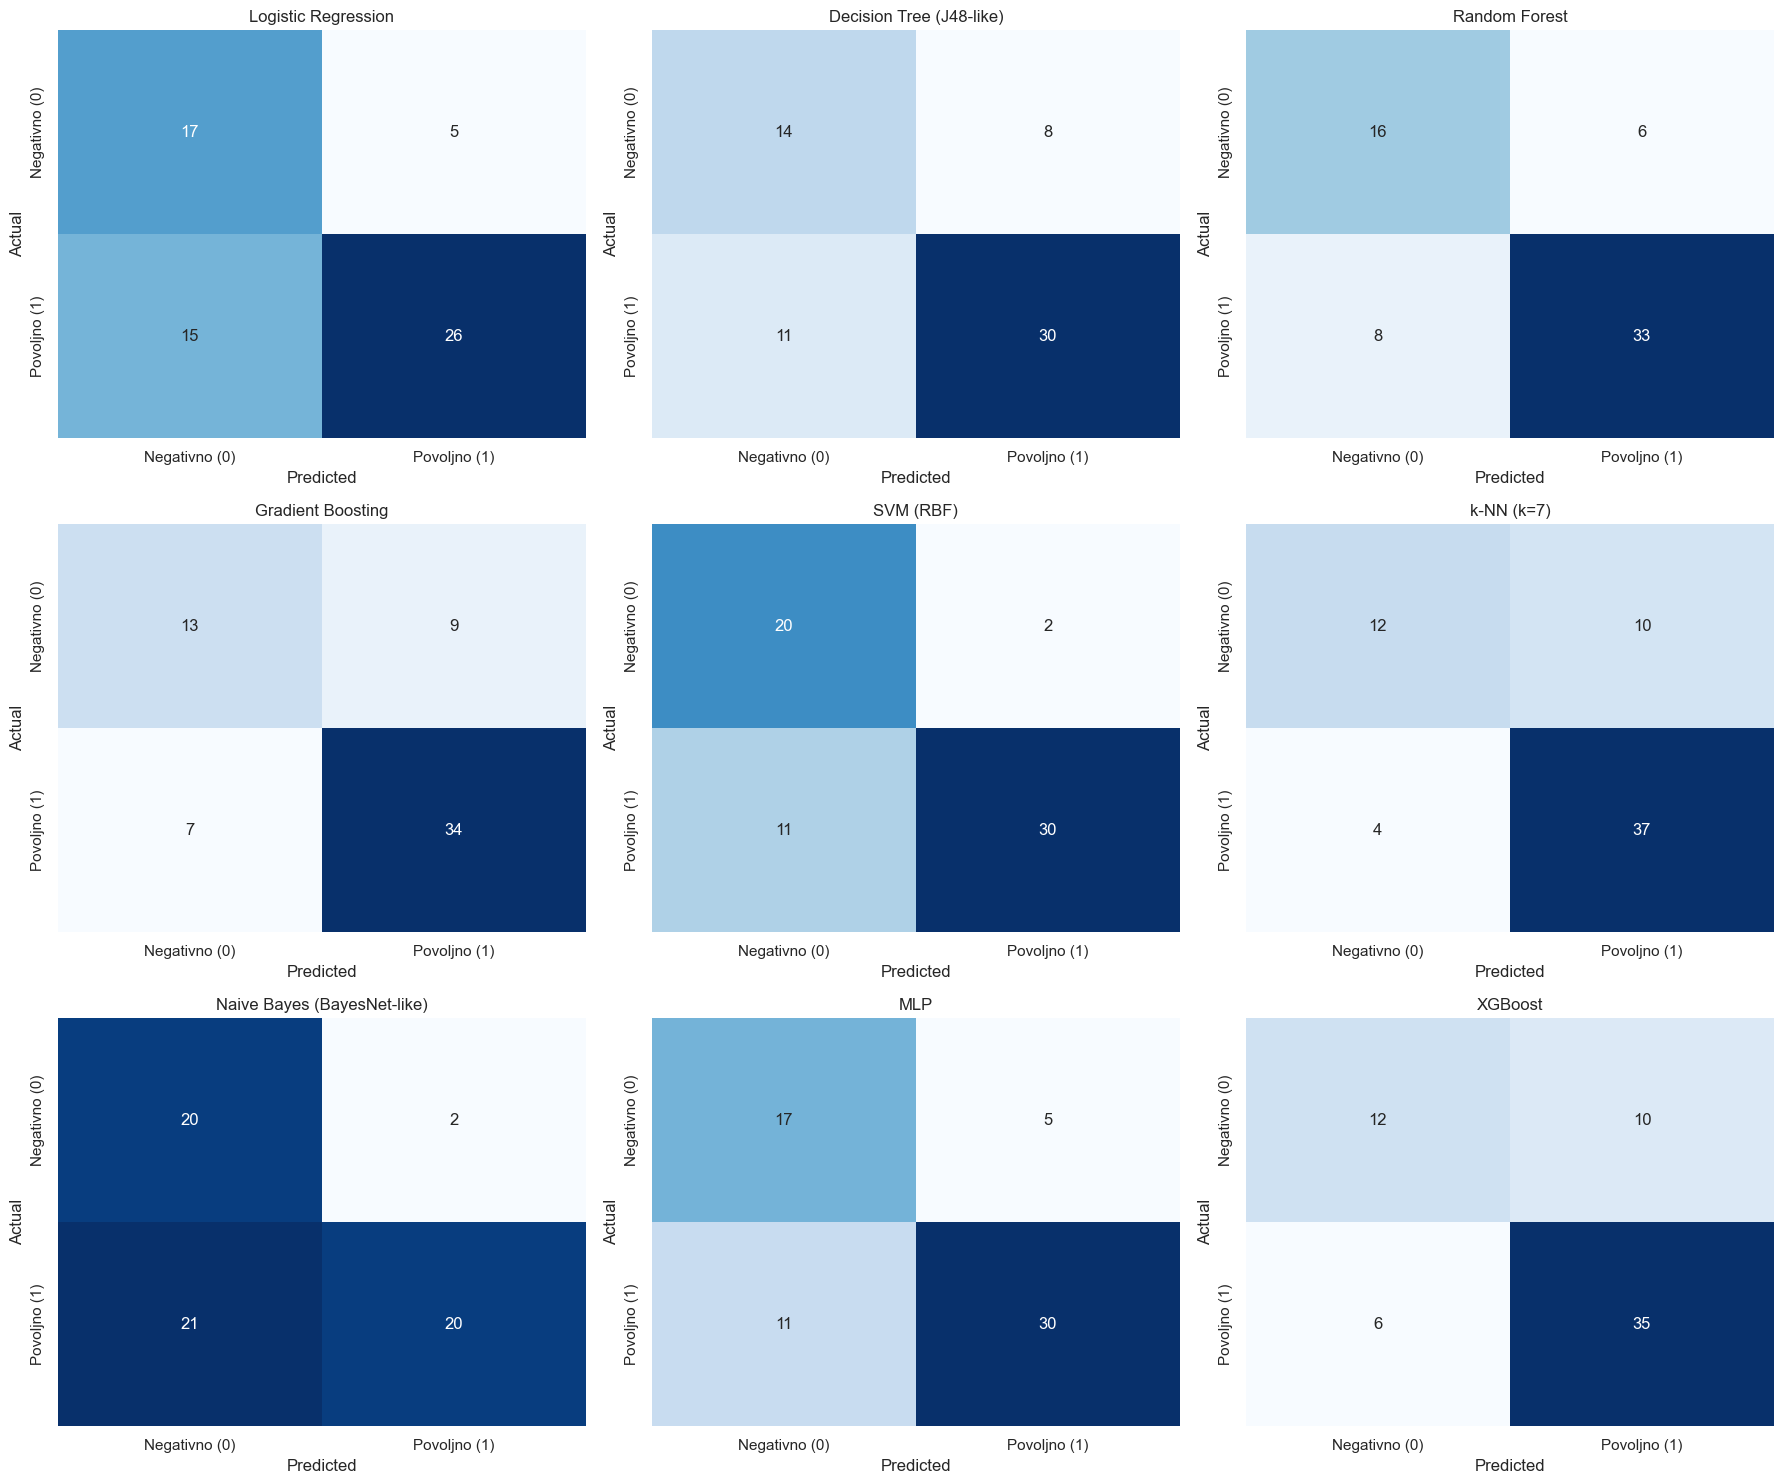


--- Numeričke vrijednosti konfuzijskih matrica ---
Logistic Regression            TN= 17 FP=  5 FN= 15 TP= 26
Decision Tree (J48-like)       TN= 14 FP=  8 FN= 11 TP= 30
Random Forest                  TN= 16 FP=  6 FN=  8 TP= 33
Gradient Boosting              TN= 13 FP=  9 FN=  7 TP= 34
SVM (RBF)                      TN= 20 FP=  2 FN= 11 TP= 30
k-NN (k=7)                     TN= 12 FP= 10 FN=  4 TP= 37
Naive Bayes (BayesNet-like)    TN= 20 FP=  2 FN= 21 TP= 20
MLP                            TN= 17 FP=  5 FN= 11 TP= 30
XGBoost                        TN= 12 FP= 10 FN=  6 TP= 35


In [31]:
nazivi_klasa = ['Negativno (0)', 'Povoljno (1)']
n_mod = len(modeli)
kolone = 3
redovi = int(np.ceil(n_mod / kolone))
fig, axes = plt.subplots(redovi, kolone, figsize=(18, 5 * redovi))
axes = axes.flatten()

for idx, (name, model) in enumerate(modeli.items()):
    model.fit(x_train, y_train)
    cm = confusion_matrix(y_test, model.predict(x_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
for j in range(n_mod, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

print("\n--- Numeričke vrijednosti konfuzijskih matrica ---")
for name, model in modeli.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(x_test)).ravel()
    print(f"{name:30s} TN={tn:3d} FP={fp:3d} FN={fn:3d} TP={tp:3d}")

U ovoj aplikaciji lažno negativni (FN) su slučajevi u kojima model procijeni povoljno mišljenje, a revizor izda negativno; to je skuplja greška od lažno pozitivnog. Zato su uz accuracy važni recall za klasu 0 i ROC-AUC.

A costly error here is predicting a favourable opinion when the auditor issues an unfavourable one; therefore recall for class 0 and ROC-AUC matter alongside accuracy.

## ROC curves - ROC krive

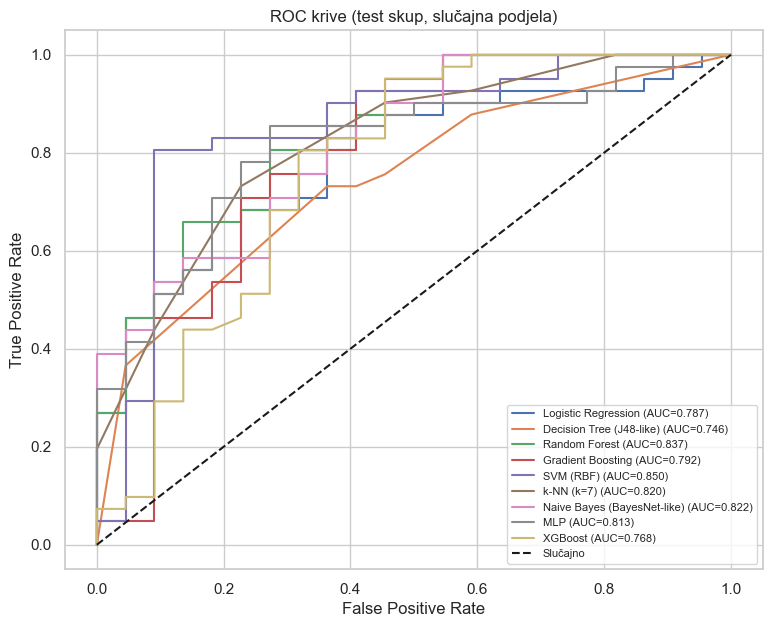

In [32]:
plt.figure(figsize=(9, 7))
for name, model in modeli.items():
    model.fit(x_train, y_train)
    proba = model.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Slučajno')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC krive (test skup, slučajna podjela)')
plt.legend(fontsize=8, loc='lower right')
plt.show()

## B) Temporal test (train <= 2019, test >= 2020) - vremenski test

In [33]:
modeli_t = napravi_modele()
res_t = {}
for name, clf in modeli_t.items():
    metrics, _, _ = evaluate_classifier(clf, x_train_t, y_train_t, x_test_t, y_test_t)
    res_t[name] = metrics
temporal_df = pd.DataFrame(res_t).T.round(4)
print(temporal_df.sort_values('ROC AUC', ascending=False))
print("\nBaseline (uvijek klasa 1): accuracy =", round(y_test_t.mean(), 4))

                             Accuracy  Precision  Recall  F1 Score  MCC  \
SVM (RBF)                        0.60       0.80    0.53      0.63 0.25   
MLP                              0.71       0.76    0.84      0.79 0.33   
k-NN (k=7)                       0.70       0.76    0.80      0.78 0.31   
Random Forest                    0.70       0.77    0.77      0.77 0.32   
Logistic Regression              0.56       0.82    0.43      0.57 0.25   
Gradient Boosting                0.65       0.73    0.76      0.74 0.21   
XGBoost                          0.62       0.71    0.73      0.72 0.15   
Naive Bayes (BayesNet-like)      0.47       0.78    0.28      0.42 0.14   
Decision Tree (J48-like)         0.62       0.72    0.72      0.72 0.16   

                             ROC AUC  
SVM (RBF)                       0.75  
MLP                             0.75  
k-NN (k=7)                      0.71  
Random Forest                   0.69  
Logistic Regression             0.69  
Gradient Boosti

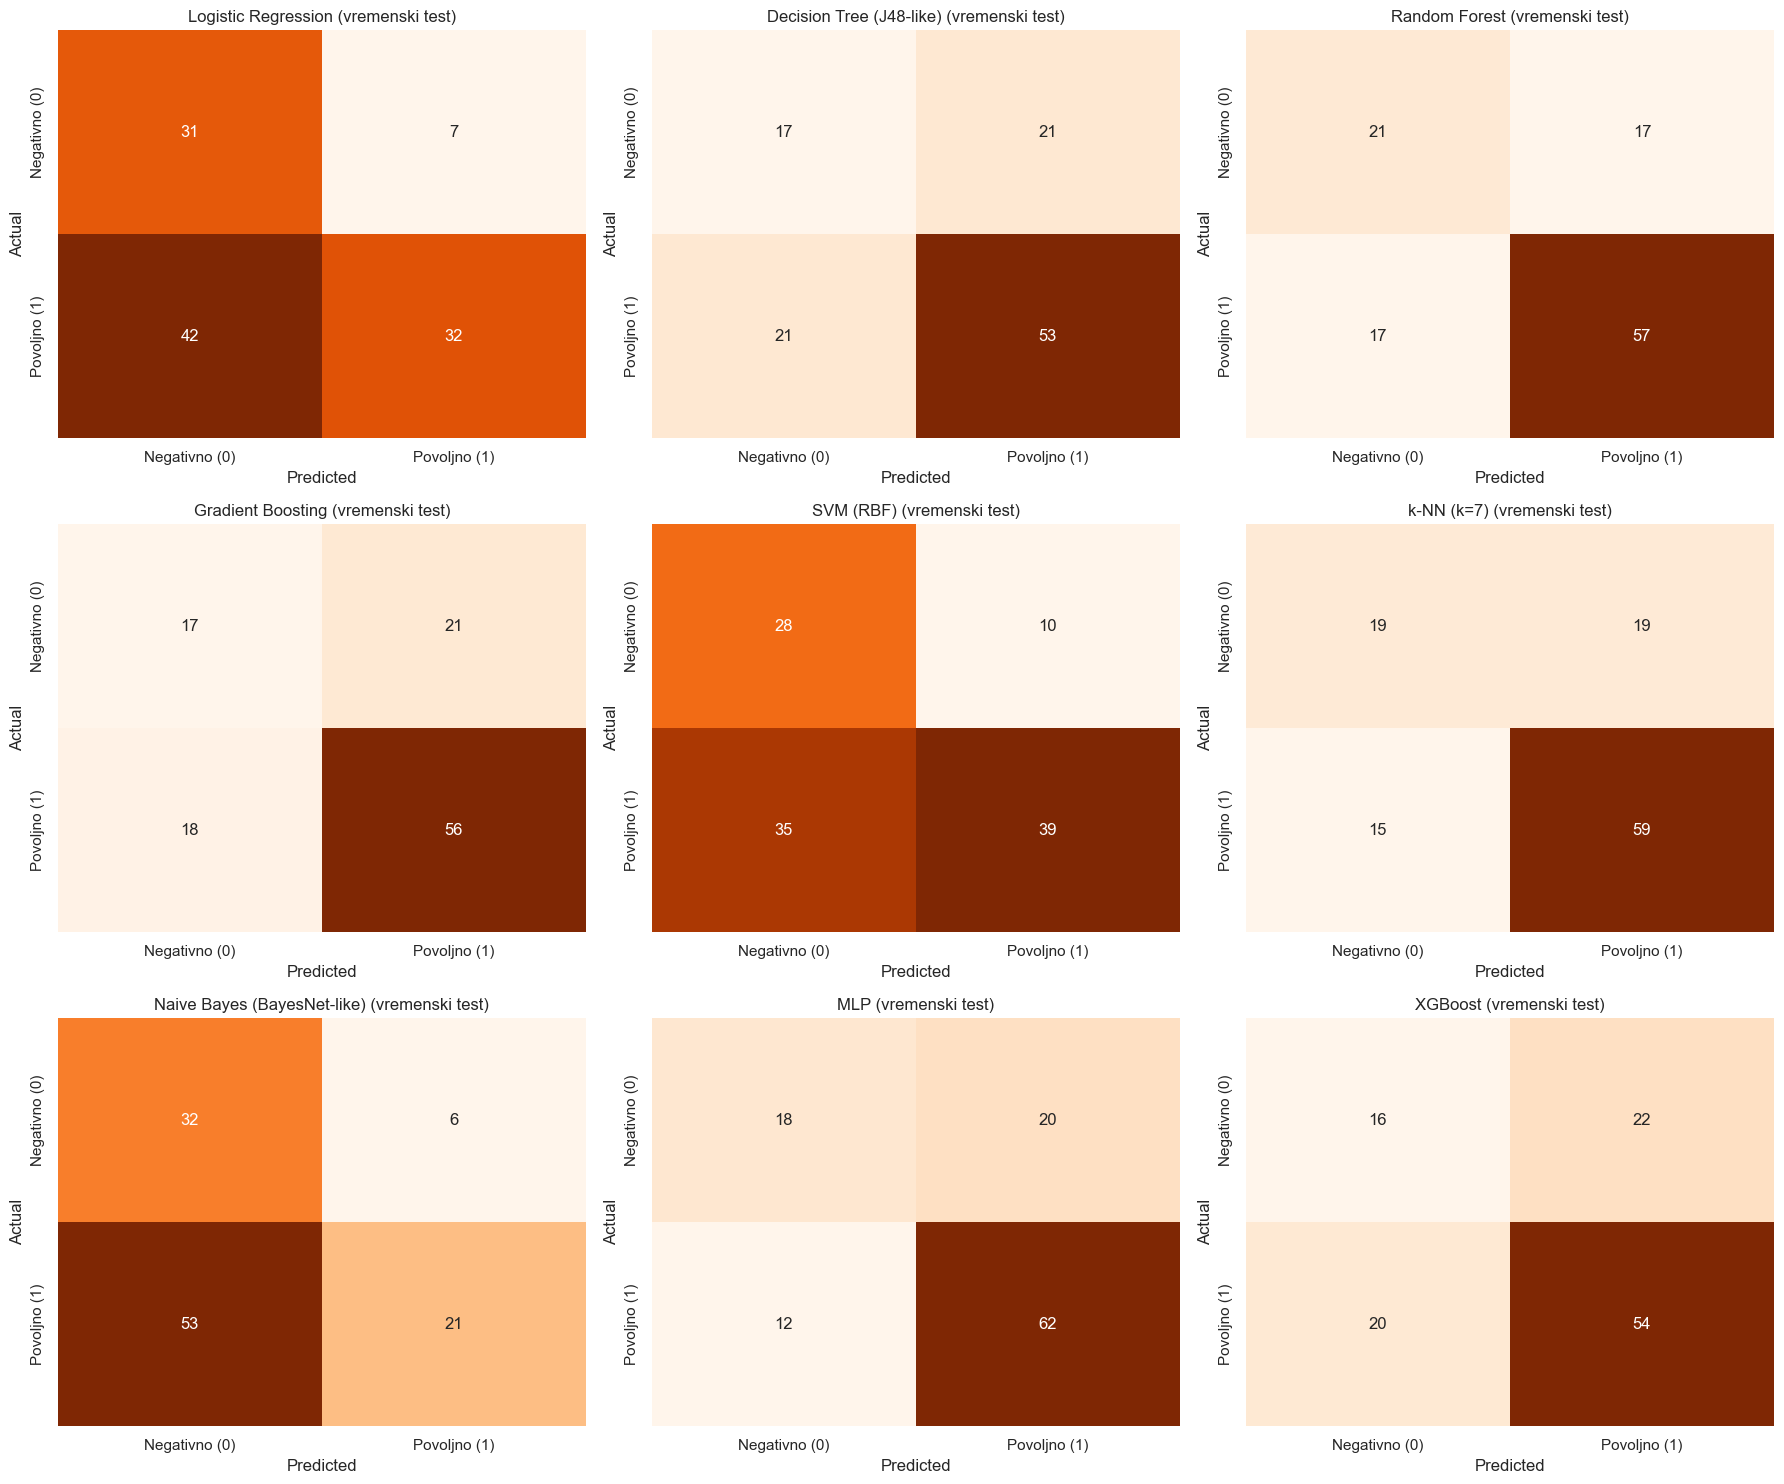

In [34]:
fig, axes = plt.subplots(redovi, kolone, figsize=(18, 5 * redovi))
axes = axes.flatten()
for idx, (name, model) in enumerate(modeli_t.items()):
    model.fit(x_train_t, y_train_t)
    cm = confusion_matrix(y_test_t, model.predict(x_test_t))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[idx], cbar=False,
                xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
    axes[idx].set_title(name + ' (vremenski test)')
    axes[idx].set_xlabel('Predicted'); axes[idx].set_ylabel('Actual')
for j in range(n_mod, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

## 10-fold cross-validation (stratified) - 10-struka križna validacija
Obavezno prema uputama; ponovljena 3 puta radi stabilnijih procjena.

In [35]:
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}

def cv_tabela(cv_factory, groups_arg=None, ponavljanja=3):
    redovi_tab = []
    for name, model in napravi_modele().items():
        sve = {m: [] for m in scoring}
        for r in range(ponavljanja):
            cv = cv_factory(r)
            if groups_arg is None:
                s = cross_validate(model, x, y, cv=cv, scoring=scoring, n_jobs=-1)
            else:
                s = cross_validate(model, x, y, cv=cv, groups=groups_arg, scoring=scoring, n_jobs=-1)
            for m in scoring:
                sve[m].append(np.mean(s[f'test_{m}']))
        redovi_tab.append({'Model': name,
                           **{f'mean_{m}': np.mean(v) for m, v in sve.items()},
                           **{f'std_{m}': np.std(v) for m, v in sve.items()}})
    return pd.DataFrame(redovi_tab).round(4).sort_values('mean_roc_auc', ascending=False)

cv10 = cv_tabela(lambda r: StratifiedKFold(n_splits=10, shuffle=True, random_state=r))
print("=== 10-FOLD CV (stratifikovana) ===")
print(cv10[['Model', 'mean_accuracy', 'mean_precision', 'mean_recall', 'mean_f1', 'mean_roc_auc', 'std_roc_auc']])

=== 10-FOLD CV (stratifikovana) ===
                         Model  mean_accuracy  mean_precision  mean_recall  \
4                    SVM (RBF)           0.72            0.82         0.72   
7                          MLP           0.73            0.78         0.81   
0          Logistic Regression           0.68            0.80         0.68   
2                Random Forest           0.71            0.75         0.84   
8                      XGBoost           0.72            0.74         0.88   
3            Gradient Boosting           0.71            0.73         0.87   
5                   k-NN (k=7)           0.70            0.74         0.84   
6  Naive Bayes (BayesNet-like)           0.55            0.76         0.45   
1     Decision Tree (J48-like)           0.60            0.72         0.64   

   mean_f1  mean_roc_auc  std_roc_auc  
4     0.76          0.79         0.01  
7     0.79          0.77         0.01  
0     0.73          0.77         0.00  
2     0.79          0.7

## 5-fold cross-validation grouped by enterprise - validacija po preduzećima
Isto preduzeće se pojavljuje u više godina; ako se te godine nađu i u trening i u test dijelu, rezultat je optimističan. `StratifiedGroupKFold` drži sve godine jednog preduzeća u istom dijelu.

In [36]:
cvg = cv_tabela(lambda r: StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r), groups_arg=groups)
print("=== 5-FOLD GROUP CV (po preduzećima) ===")
print(cvg[['Model', 'mean_accuracy', 'mean_precision', 'mean_recall', 'mean_f1', 'mean_roc_auc', 'std_roc_auc']])

=== 5-FOLD GROUP CV (po preduzećima) ===
                         Model  mean_accuracy  mean_precision  mean_recall  \
7                          MLP           0.69            0.76         0.77   
0          Logistic Regression           0.66            0.78         0.66   
4                    SVM (RBF)           0.68            0.79         0.70   
2                Random Forest           0.70            0.73         0.86   
5                   k-NN (k=7)           0.68            0.72         0.83   
8                      XGBoost           0.69            0.72         0.85   
6  Naive Bayes (BayesNet-like)           0.55            0.75         0.47   
3            Gradient Boosting           0.69            0.72         0.85   
1     Decision Tree (J48-like)           0.61            0.70         0.66   

   mean_f1  mean_roc_auc  std_roc_auc  
7     0.76          0.73         0.01  
0     0.71          0.73         0.01  
4     0.73          0.73         0.01  
2     0.79        

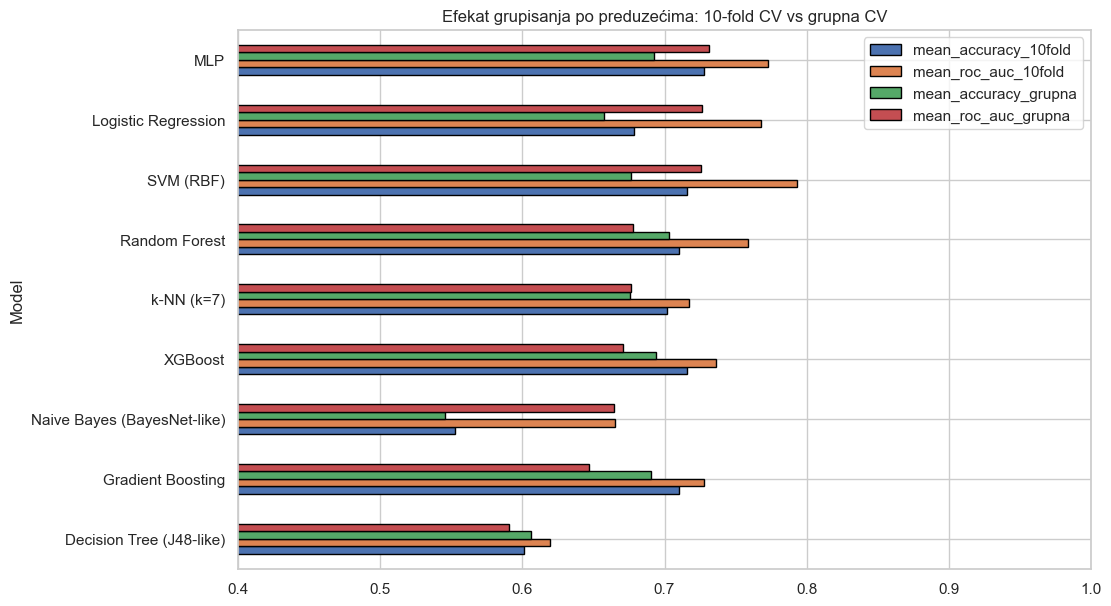

                             mean_accuracy_10fold  mean_roc_auc_10fold  \
Model                                                                    
SVM (RBF)                                    0.72                 0.79   
MLP                                          0.73                 0.77   
Logistic Regression                          0.68                 0.77   
Random Forest                                0.71                 0.76   
XGBoost                                      0.72                 0.74   
Gradient Boosting                            0.71                 0.73   
k-NN (k=7)                                   0.70                 0.72   
Naive Bayes (BayesNet-like)                  0.55                 0.67   
Decision Tree (J48-like)                     0.60                 0.62   

                             mean_accuracy_grupna  mean_roc_auc_grupna  
Model                                                                   
SVM (RBF)                              

In [37]:
poredjenje = cv10.set_index('Model')[['mean_accuracy', 'mean_roc_auc']].join(
    cvg.set_index('Model')[['mean_accuracy', 'mean_roc_auc']], lsuffix='_10fold', rsuffix='_grupna')
poredjenje.sort_values('mean_roc_auc_grupna').plot(kind='barh', figsize=(11, 7), edgecolor='black')
plt.title('Efekat grupisanja po preduzećima: 10-fold CV vs grupna CV')
plt.xlim(0.4, 1.0)
plt.show()
print(poredjenje.round(3))

Razlika između običnog i grupnog CV pokazuje koliko bi rezultat bio napuhan zbog ponavljanja istog preduzeća. Za izvještavanje se preporučuje grupna ili vremenska varijanta.

The gap between plain and grouped CV shows how much results would be inflated by repeated enterprises. Grouped or temporal results are recommended for reporting.

## Does sector help? - da li sektor poboljšava model
Poređenje skupa A (samo bilansne pozicije) i skupa B (bilansne pozicije + sektor, one-hot).

In [38]:
x_sek = pd.concat([x, pd.get_dummies(df['Sektor'], prefix='sek').astype(int)], axis=1)

def grupni_cv_skup(X_skup, model_fn, ponavljanja=5):
    out = []
    for r in range(ponavljanja):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
        s = cross_validate(model_fn(), X_skup, y, cv=cv, groups=groups, scoring=['accuracy', 'roc_auc', 'f1'])
        out.append([np.mean(s['test_accuracy']), np.mean(s['test_roc_auc']), np.mean(s['test_f1'])])
    return np.mean(out, axis=0)

tab = []
for ime, fn in [("Random Forest", lambda: napravi_modele()["Random Forest"]),
                ("Logistic Regression", lambda: napravi_modele()["Logistic Regression"]),
                ("Gradient Boosting", lambda: napravi_modele()["Gradient Boosting"])]:
    a = grupni_cv_skup(x, fn); b = grupni_cv_skup(x_sek, fn)
    tab.append({'Model': ime, 'Acc (bez sektora)': a[0], 'Acc (sa sektorom)': b[0],
                'AUC (bez sektora)': a[1], 'AUC (sa sektorom)': b[1]})
sektor_df = pd.DataFrame(tab).round(3)
print(sektor_df)

                 Model  Acc (bez sektora)  Acc (sa sektorom)  \
0        Random Forest               0.71               0.71   
1  Logistic Regression               0.66               0.65   
2    Gradient Boosting               0.69               0.67   

   AUC (bez sektora)  AUC (sa sektorom)  
0               0.69               0.69  
1               0.73               0.70  
2               0.65               0.66  


## Attribute selection - selekcija atributa (InfoGain, CFS)
Prema uputama dokumentujemo rang atributa. Rang ispod je izračunat na cijelom skupu i služi **za dokumentaciju**; kod poređenja skupova atributa selekcija se ponavlja unutar svakog folda (inače bi rezultat bio optimistično pristrasan).

In [39]:
Xd = _diskretizuj(x, 5)
yy = y.values.astype(int)
ig = np.array([_mi_bits(Xd[:, j], yy) for j in range(Xd.shape[1])])
su_cls = np.array([_su(Xd[:, j], yy) for j in range(Xd.shape[1])])
cfs_full = CFSSelector().fit(x, y)

rang_atributa = pd.DataFrame({
    'Atribut': numericke,
    'InfoGain (bit)': ig,
    'Symmetrical uncertainty': su_cls,
    'CFS odabran': ['da' if i in set(cfs_full.support_) else '' for i in range(len(numericke))]
}).sort_values('InfoGain (bit)', ascending=False).reset_index(drop=True)
rang_atributa.insert(0, 'Rang', np.arange(1, len(rang_atributa) + 1))
print(rang_atributa.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nCFS odabrani atributi (merit = %.4f):" % cfs_full.merit_)
print([numericke[i] for i in cfs_full.support_])

 Rang                Atribut  InfoGain (bit)  Symmetrical uncertainty CFS odabran
    1       obrtna_imovina_t          0.0588                   0.0361          da
    2      obrtna_imovina_t1          0.0481                   0.0295            
    3   potrazivanja_kupci_t          0.0440                   0.0270          da
    4     poslovna_imovina_t          0.0436                   0.0268          da
    5    poslovna_imovina_t1          0.0385                   0.0236            
    6 novcani_tok_poslovni_t          0.0355                   0.0218          da
    7  potrazivanja_kupci_t1          0.0319                   0.0195            
    8       dugor_obaveze_t1          0.0315                   0.0220          da
    9        dugor_obaveze_t          0.0294                   0.0206            
   10   nekretnine_oprema_t1          0.0263                   0.0161            
   11    nekretnine_oprema_t          0.0213                   0.0131            
   12       krat

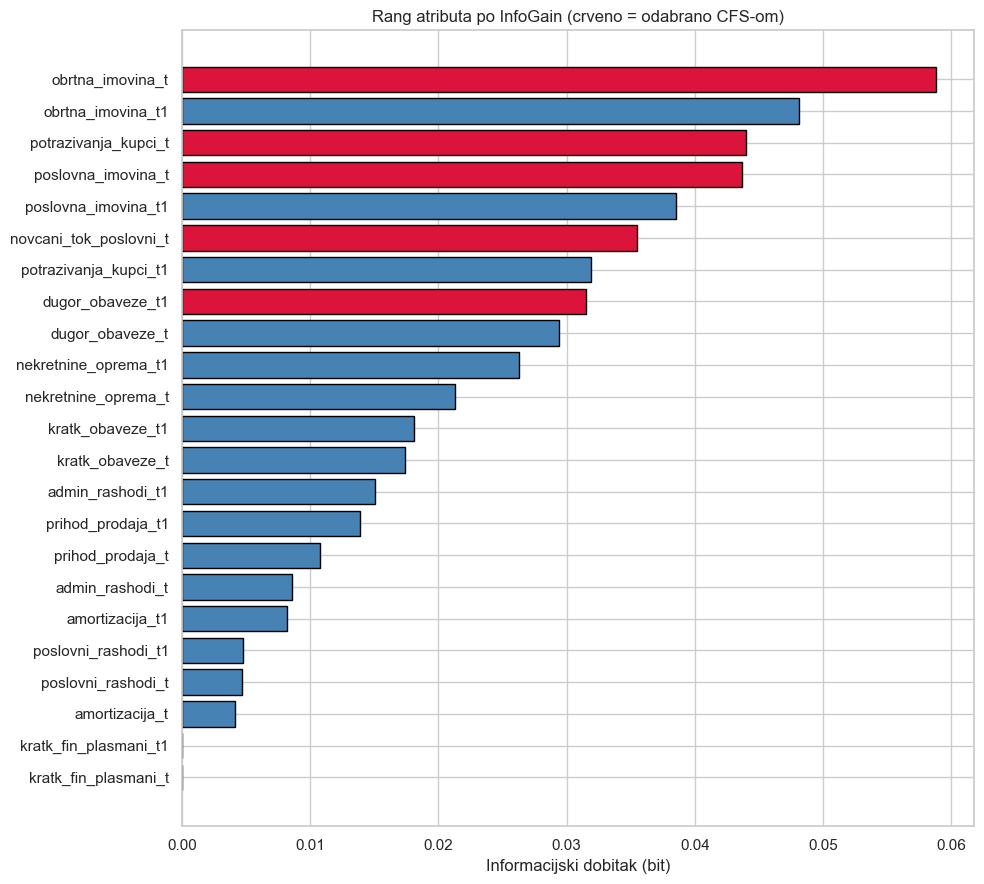

In [40]:
ra = rang_atributa.iloc[::-1]
boje = ['crimson' if c == 'da' else 'steelblue' for c in ra['CFS odabran']]
plt.figure(figsize=(10, 9))
plt.barh(ra['Atribut'], ra['InfoGain (bit)'], color=boje, edgecolor='black')
plt.xlabel('Informacijski dobitak (bit)')
plt.title('Rang atributa po InfoGain (crveno = odabrano CFS-om)')
plt.tight_layout()
plt.show()

Informacijski dobitak je za sve atribute vrlo mali (reda stotih dijelova bita), što potvrđuje slabe pojedinačne veze s mišljenjem. Zato se očekuje da nijedan podskup ne donese velik skok tačnosti; razlike se provjeravaju statistički u sekcijama ispod.

## Feature set comparison - poređenje skupova atributa (H2)
Skupovi: **S1** svih 23 pozicije; **S2** skup A iz uputa (šest od sedam pozicija iz rada koje postoje u bazi; „dobit/gubitak na kraju perioda“ nema kolonu); **S3** skup A + približni operativni rezultat (prihod − poslovni rashodi); **S4** InfoGain top-10; **S5** CFS; **S6** finansijski omjeri; **S7** sirove pozicije + omjeri.

Svi modeli se ocjenjuju **grupnom** 5-fold CV po preduzećima, ponovljenom `N_REPEATS` puta (iste podjele za sve modele, pa su poređenja uparena). Selekcija atributa (S4, S5) odvija se unutar svakog folda.

In [41]:
N_REPEATS = 3        # smanjiti na 1 za brzo testiranje; 3 daje stabilnije procjene
N_SPLITS = 5

omjeri = izracunaj_omjere(df)
skup_A = ['potrazivanja_kupci_t1', 'potrazivanja_kupci_t', 'poslovna_imovina_t', 'poslovna_imovina_t1',
          'kratk_fin_plasmani_t', 'kratk_fin_plasmani_t1']
op_rez = (df['prihod_prodaja_t'] - df['poslovni_rashodi_t']).rename('op_rezultat_t')

SKUPOVI = {
    'S1 Sve pozicije (23)':          dict(X=x,                                     sel=None,                       winsor=False),
    'S2 Skup A iz uputa (6)':        dict(X=x[skup_A],                             sel=None,                       winsor=False),
    'S3 Skup A + op. rezultat (7)':  dict(X=pd.concat([x[skup_A], op_rez], axis=1), sel=None,                      winsor=False),
    'S4 InfoGain top-10':            dict(X=x,                                     sel=lambda: InfoGainSelector(10), winsor=False),
    'S5 CFS':                        dict(X=x,                                     sel=lambda: CFSSelector(),      winsor=False),
    'S6 Omjeri (19)':                dict(X=omjeri,                                sel=None,                       winsor=True),
    'S7 Sirove + omjeri (42)':       dict(X=pd.concat([x, omjeri], axis=1),        sel=None,                       winsor=True),
}
for k, v in SKUPOVI.items():
    print(f"{k:32s} atributa: {v['X'].shape[1]}")

def modeli_za_skup(naziv):
    cfg = SKUPOVI[naziv]
    return napravi_modele(selector_fn=cfg['sel'], winsor=cfg['winsor'])

from sklearn.metrics import make_scorer
scoring_ext = {
    'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'f1': 'f1', 'f1_macro': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy', 'mcc': make_scorer(matthews_corrcoef),
    'recall_neg': make_scorer(recall_score, pos_label=0),
    'precision_neg': make_scorer(precision_score, pos_label=0, zero_division=0),
}

def cv_scores(model, X, yy, kind='group', repeats=None, scoring=None):
    """Vraća rezultate po foldu (svi repeat-i spojeni). Iste podjele za sve modele (random_state = redni broj ponavljanja)."""
    repeats = repeats or N_REPEATS
    scoring = scoring or scoring_ext
    out = {k: [] for k in scoring}
    for r in range(repeats):
        if kind == 'group':
            cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=r)
            kw = dict(groups=groups)
        else:
            cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=r)
            kw = {}
        s = cross_validate(model, X, yy, cv=cv, scoring=scoring, n_jobs=-1, **kw)
        for k in out:
            out[k].extend(s['test_' + k])
    return {k: np.array(v) for k, v in out.items()}

S1 Sve pozicije (23)             atributa: 23
S2 Skup A iz uputa (6)           atributa: 6
S3 Skup A + op. rezultat (7)     atributa: 7
S4 InfoGain top-10               atributa: 23
S5 CFS                           atributa: 23
S6 Omjeri (19)                   atributa: 19
S7 Sirove + omjeri (42)          atributa: 42


In [42]:
REZ = {}
for naziv in SKUPOVI:
    for mname, model in modeli_za_skup(naziv).items():
        REZ[(naziv, mname)] = cv_scores(model, SKUPOVI[naziv]['X'], y, kind='group')
    print("gotovo:", naziv)
agg = pd.DataFrame([{'Skup': s, 'Model': m, **{k: v.mean() for k, v in d.items()}} for (s, m), d in REZ.items()])
print("\nBroj fold-ova po konfiguraciji:", len(next(iter(REZ.values()))['roc_auc']))

gotovo: S1 Sve pozicije (23)
gotovo: S2 Skup A iz uputa (6)
gotovo: S3 Skup A + op. rezultat (7)
gotovo: S4 InfoGain top-10
gotovo: S5 CFS
gotovo: S6 Omjeri (19)
gotovo: S7 Sirove + omjeri (42)

Broj fold-ova po konfiguraciji: 15


=== ROC AUC (grupna CV, srednja vrijednost) ===
Model                         Decision Tree (J48-like)  Gradient Boosting  Logistic Regression   MLP  Naive Bayes (BayesNet-like)  Random Forest  SVM (RBF)  XGBoost  k-NN (k=7)
Skup                                                                                                                                                                            
S1 Sve pozicije (23)                             0.591              0.647                0.726 0.732                        0.664          0.678      0.726    0.671       0.676
S2 Skup A iz uputa (6)                           0.583              0.584                0.631 0.678                        0.667          0.620      0.662    0.604       0.593
S3 Skup A + op. rezultat (7)                     0.562              0.604                0.650 0.649                        0.671          0.611      0.681    0.608       0.634
S4 InfoGain top-10                               0.546             

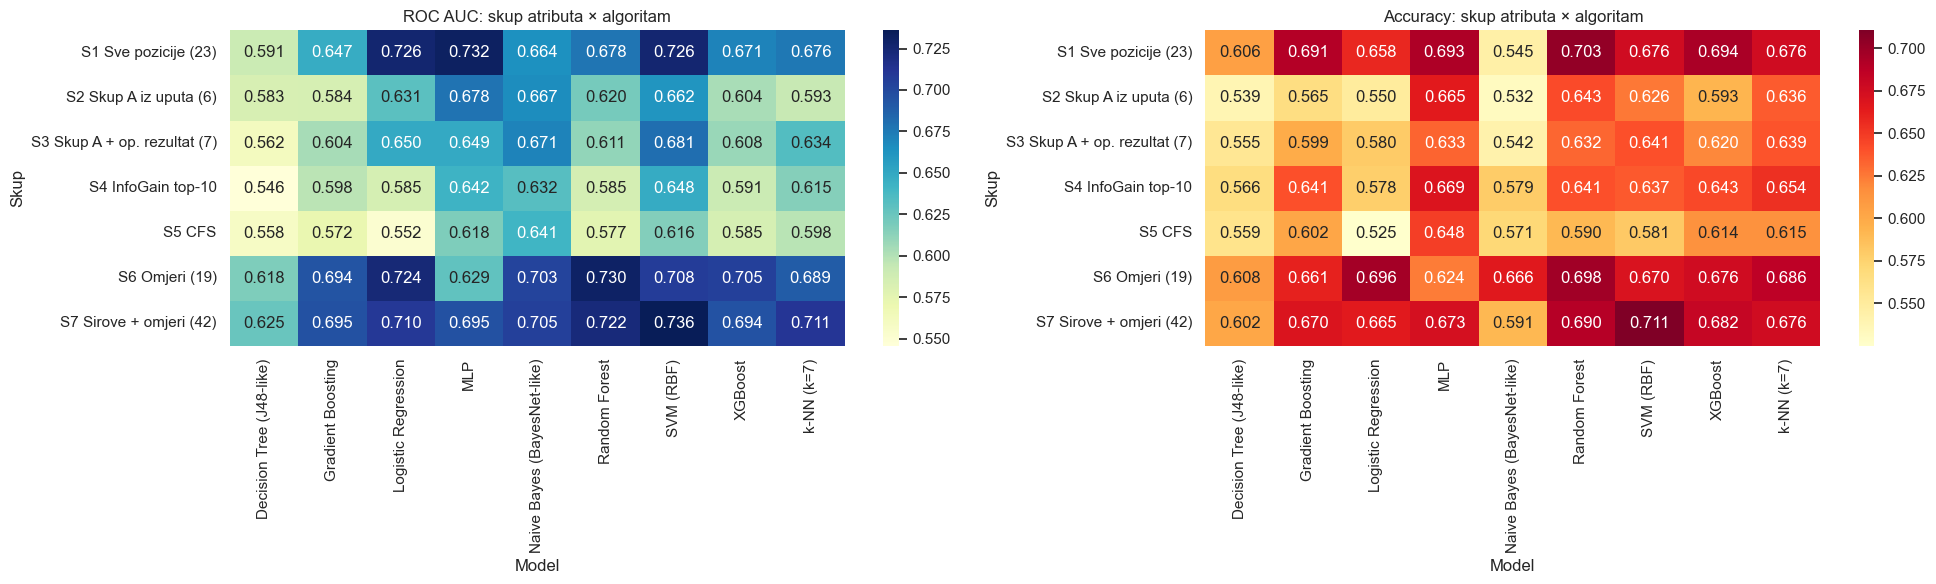


Prosječni AUC po skupu atributa (preko algoritama):
Skup
S7 Sirove + omjeri (42)        0.699
S6 Omjeri (19)                 0.689
S1 Sve pozicije (23)           0.679
S3 Skup A + op. rezultat (7)   0.630
S2 Skup A iz uputa (6)         0.625
S4 InfoGain top-10             0.605
S5 CFS                         0.591
dtype: float64

Prosječni AUC po algoritmu (preko skupova atributa):
Model
SVM (RBF)                     0.682
Naive Bayes (BayesNet-like)   0.669
MLP                           0.663
Logistic Regression           0.654
Random Forest                 0.646
k-NN (k=7)                    0.645
XGBoost                       0.637
Gradient Boosting             0.628
Decision Tree (J48-like)      0.583
dtype: float64

Najbolja kombinacija po AUC:
                       Skup                Model  roc_auc  accuracy    f1   mcc  recall_neg  precision_neg
58  S7 Sirove + omjeri (42)            SVM (RBF)    0.736     0.711 0.762 0.378       0.667          0.557
7      S1 Sve pozicije (2

In [43]:
pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 250
pd.options.display.max_columns = 40
pivot_auc = agg.pivot(index='Skup', columns='Model', values='roc_auc')
pivot_acc = agg.pivot(index='Skup', columns='Model', values='accuracy')
print("=== ROC AUC (grupna CV, srednja vrijednost) ===")
print(pivot_auc)
print("\n=== Accuracy (grupna CV) ===")
print(pivot_acc)

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(pivot_auc, annot=True, fmt='.3f', cmap='YlGnBu', ax=axes[0])
axes[0].set_title('ROC AUC: skup atributa × algoritam')
sns.heatmap(pivot_acc, annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('Accuracy: skup atributa × algoritam')
plt.tight_layout()
plt.show()

print("\nProsječni AUC po skupu atributa (preko algoritama):")
print(pivot_auc.mean(axis=1).sort_values(ascending=False))
print("\nProsječni AUC po algoritmu (preko skupova atributa):")
print(pivot_auc.mean(axis=0).sort_values(ascending=False))
print("\nNajbolja kombinacija po AUC:")
print(agg.sort_values('roc_auc', ascending=False).head(8)[['Skup', 'Model', 'roc_auc', 'accuracy', 'f1', 'mcc', 'recall_neg', 'precision_neg']])

## Statistical tests - statistički testovi (H1 i H2)
- **Friedmanov test** među algoritmima (blokovi = fold-ovi) i među skupovima atributa.
- **Korigovani resampled t-test** (Nadeau i Bengio) za uparena poređenja, jer fold-ovi iz ponovljene CV nisu nezavisni. Za više poređenja primijenjena je Holmova korekcija.
- **H1:** najbolja kombinacija naspram osnovnog nivoa (`DummyClassifier`, većinska klasa) po tačnosti i AUC.

In [44]:
from scipy.stats import friedmanchisquare, t as t_dist

def korigovani_t(d, n_train, n_test):
    d = np.asarray(d, float)
    J = len(d)
    v = d.var(ddof=1)
    if v == 0:
        return np.nan, np.nan
    t_stat = d.mean() / np.sqrt((1 / J + n_test / n_train) * v)
    return t_stat, 2 * t_dist.sf(abs(t_stat), J - 1)

def holm(pvals):
    p = np.array(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    prev = 0
    for rank, idx in enumerate(order):
        prev = max(prev, (m - rank) * p[idx])
        adj[idx] = min(1.0, prev)
    return adj

n_uk = len(df)
n_test_f = n_uk / N_SPLITS
n_train_f = n_uk - n_test_f
modeli_nazivi = list(napravi_modele().keys())
skupovi_nazivi = list(SKUPOVI.keys())

# --- osnovni nivo
REZ_dummy = cv_scores(DummyClassifier(strategy='prior'), x, y, kind='group')

# --- H2a: Friedman među algoritmima (na svakom skupu atributa)
red_a = []
for s in skupovi_nazivi:
    mat = np.column_stack([REZ[(s, m)]['roc_auc'] for m in modeli_nazivi])
    stat, p = friedmanchisquare(*[mat[:, j] for j in range(mat.shape[1])])
    red_a.append({'Skup': s, 'Friedman chi2': stat, 'p': p, 'Značajno (p<0.05)': 'da' if p < 0.05 else 'ne'})
friedman_algoritmi = pd.DataFrame(red_a)
print("=== H2a: razlikuju li se ALGORITMI (AUC, fold-ovi kao blokovi) ===")
print(friedman_algoritmi.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# --- H2b: Friedman među skupovima atributa (za svaki algoritam)
red_b = []
for m in modeli_nazivi:
    mat = np.column_stack([REZ[(s, m)]['roc_auc'] for s in skupovi_nazivi])
    stat, p = friedmanchisquare(*[mat[:, j] for j in range(mat.shape[1])])
    red_b.append({'Algoritam': m, 'Friedman chi2': stat, 'p': p, 'Značajno (p<0.05)': 'da' if p < 0.05 else 'ne'})
friedman_skupovi = pd.DataFrame(red_b)
print("\n=== H2b: razlikuju li se SKUPOVI ATRIBUTA (AUC, po algoritmu) ===")
print(friedman_skupovi.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Friedman na prosjeku preko algoritama
mat_s = np.column_stack([np.mean([REZ[(s, m)]['roc_auc'] for m in modeli_nazivi], axis=0) for s in skupovi_nazivi])
stat_s, p_friedman_skupovi_prosjek = friedmanchisquare(*[mat_s[:, j] for j in range(mat_s.shape[1])])
print(f"\nFriedman među skupovima (AUC usrednjen preko algoritama): chi2 = {stat_s:.3f}, p = {p_friedman_skupovi_prosjek:.4f}")

# --- H1: najbolja kombinacija vs osnovni nivo
najbolji_red = agg.sort_values('roc_auc', ascending=False).iloc[0]
b_set, b_model = najbolji_red['Skup'], najbolji_red['Model']
sc_b = REZ[(b_set, b_model)]
t_acc, p_acc = korigovani_t(sc_b['accuracy'] - REZ_dummy['accuracy'], n_train_f, n_test_f)
t_auc, p_auc = korigovani_t(sc_b['roc_auc'] - REZ_dummy['roc_auc'], n_train_f, n_test_f)
p_h1_acc = p_acc / 2 if t_acc > 0 else 1 - p_acc / 2        # jednostrani
p_h1_auc = p_auc / 2 if t_auc > 0 else 1 - p_auc / 2
print(f"\n=== H1: najbolja kombinacija = {b_set} + {b_model} ===")
print(f"Accuracy: model {sc_b['accuracy'].mean():.3f} vs osnovni nivo {REZ_dummy['accuracy'].mean():.3f}; t = {t_acc:.2f}, jednostrani p = {p_h1_acc:.4f}")
print(f"ROC AUC:  model {sc_b['roc_auc'].mean():.3f} vs slučajno 0.500;           t = {t_auc:.2f}, jednostrani p = {p_h1_auc:.4f}")

# --- uparena poređenja algoritama na S1 (korigovani t-test + Holm), referentni = najbolji na S1
s_ref = skupovi_nazivi[0]
best_s1 = max(modeli_nazivi, key=lambda m: REZ[(s_ref, m)]['roc_auc'].mean())
red_p = []
for m in modeli_nazivi:
    if m == best_s1:
        continue
    t_, p_ = korigovani_t(REZ[(s_ref, best_s1)]['roc_auc'] - REZ[(s_ref, m)]['roc_auc'], n_train_f, n_test_f)
    red_p.append({'Poređenje': f"{best_s1} vs {m}", 'razlika AUC': (REZ[(s_ref, best_s1)]['roc_auc'] - REZ[(s_ref, m)]['roc_auc']).mean(), 't': t_, 'p': p_})
tab_p = pd.DataFrame(red_p)
tab_p['p (Holm)'] = holm(tab_p['p'].values)
tab_p['Značajno (Holm<0.05)'] = np.where(tab_p['p (Holm)'] < 0.05, 'da', 'ne')
print(f"\n=== Uparena poređenja na {s_ref}: najbolji algoritam ({best_s1}) naspram ostalih ===")
print(tab_p.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# --- uparena poređenja skupova atributa za najbolji algoritam (referentni: S1)
red_q = []
for s in skupovi_nazivi[1:]:
    d_ = REZ[(s, b_model)]['roc_auc'] - REZ[(skupovi_nazivi[0], b_model)]['roc_auc']
    t_, p_ = korigovani_t(d_, n_train_f, n_test_f)
    red_q.append({'Skup': s, 'razlika AUC vs S1': d_.mean(), 't': t_, 'p': p_})
tab_q = pd.DataFrame(red_q)
tab_q['p (Holm)'] = holm(tab_q['p'].values)
tab_q['Značajno (Holm<0.05)'] = np.where(tab_q['p (Holm)'] < 0.05, 'da', 'ne')
print(f"\n=== Skupovi atributa naspram S1, algoritam: {b_model} ===")
print(tab_q.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

=== H2a: razlikuju li se ALGORITMI (AUC, fold-ovi kao blokovi) ===
                        Skup  Friedman chi2      p Značajno (p<0.05)
        S1 Sve pozicije (23)        42.9471 0.0000                da
      S2 Skup A iz uputa (6)        40.2938 0.0000                da
S3 Skup A + op. rezultat (7)        34.4650 0.0000                da
          S4 InfoGain top-10        33.1695 0.0001                da
                      S5 CFS        19.3752 0.0130                da
              S6 Omjeri (19)        52.1290 0.0000                da
     S7 Sirove + omjeri (42)        25.2992 0.0014                da

=== H2b: razlikuju li se SKUPOVI ATRIBUTA (AUC, po algoritmu) ===
                  Algoritam  Friedman chi2      p Značajno (p<0.05)
        Logistic Regression        48.4286 0.0000                da
   Decision Tree (J48-like)        11.5274 0.0734                ne
              Random Forest        48.5714 0.0000                da
          Gradient Boosting        38.2339

**Kako čitati:** male p-vrijednosti u Friedmanovom testu znače da je barem jedna razlika među algoritmima (ili skupovima) stvarna. Nakon Holmove korekcije većina uparenih razlika obično nije značajna, jer su razlike među dobrim modelima unutar šuma. Za H1 gledamo da li model značajno nadmašuje osnovni nivo, a ne da li je „najbolji“.

## Best model selection - izbor najboljeg modela
Kriterij izbora: najveći srednji ROC AUC u grupnoj CV (preko svih kombinacija skup × algoritam). Pošto se bira među mnogo kombinacija, ova procjena je blago optimistična; zato je nezavisno potvrđujemo kliznom vremenskom validacijom (sekcija ispod).

Za izabrani skup atributa dobijaju se *out-of-fold* predikcije (svaki izvještaj ocjenjuje model koji ga nije vidio, a preduzeće nije u treningu), iz kojih se računaju konfuziona matrica, ROC i PR krive, izvještaj po klasama i intervali povjerenja.

In [45]:
best_set, best_model = b_set, b_model
X_best = SKUPOVI[best_set]['X']
print("Izabrano:", best_set, "+", best_model)

from sklearn.model_selection import cross_val_predict
cv_oof = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)
OOF = {}
for mname, model in modeli_za_skup(best_set).items():
    OOF[mname] = cross_val_predict(model, X_best, y, cv=cv_oof, groups=groups, method='predict_proba')[:, 1]
oof_best = OOF[best_model]
pred_best = (oof_best >= 0.5).astype(int)

print("\n--- Izvještaj po klasama (out-of-fold, prag 0.5) ---")
print(classification_report(y, pred_best, target_names=['Negativno (0) - RIZIK', 'Povoljno (1)'], digits=3))
print("ROC AUC:", round(roc_auc_score(y, oof_best), 3), "| MCC:", round(matthews_corrcoef(y, pred_best), 3),
      "| Accuracy:", round(accuracy_score(y, pred_best), 3), "| osnovni nivo:", round(y.mean(), 3))

Izabrano: S7 Sirove + omjeri (42) + SVM (RBF)

--- Izvještaj po klasama (out-of-fold, prag 0.5) ---
                       precision    recall  f1-score   support

Negativno (0) - RIZIK      0.638     0.396     0.489       111
         Povoljno (1)      0.724     0.876     0.793       201

             accuracy                          0.705       312
            macro avg      0.681     0.636     0.641       312
         weighted avg      0.693     0.705     0.685       312

ROC AUC: 0.734 | MCC: 0.314 | Accuracy: 0.705 | osnovni nivo: 0.644


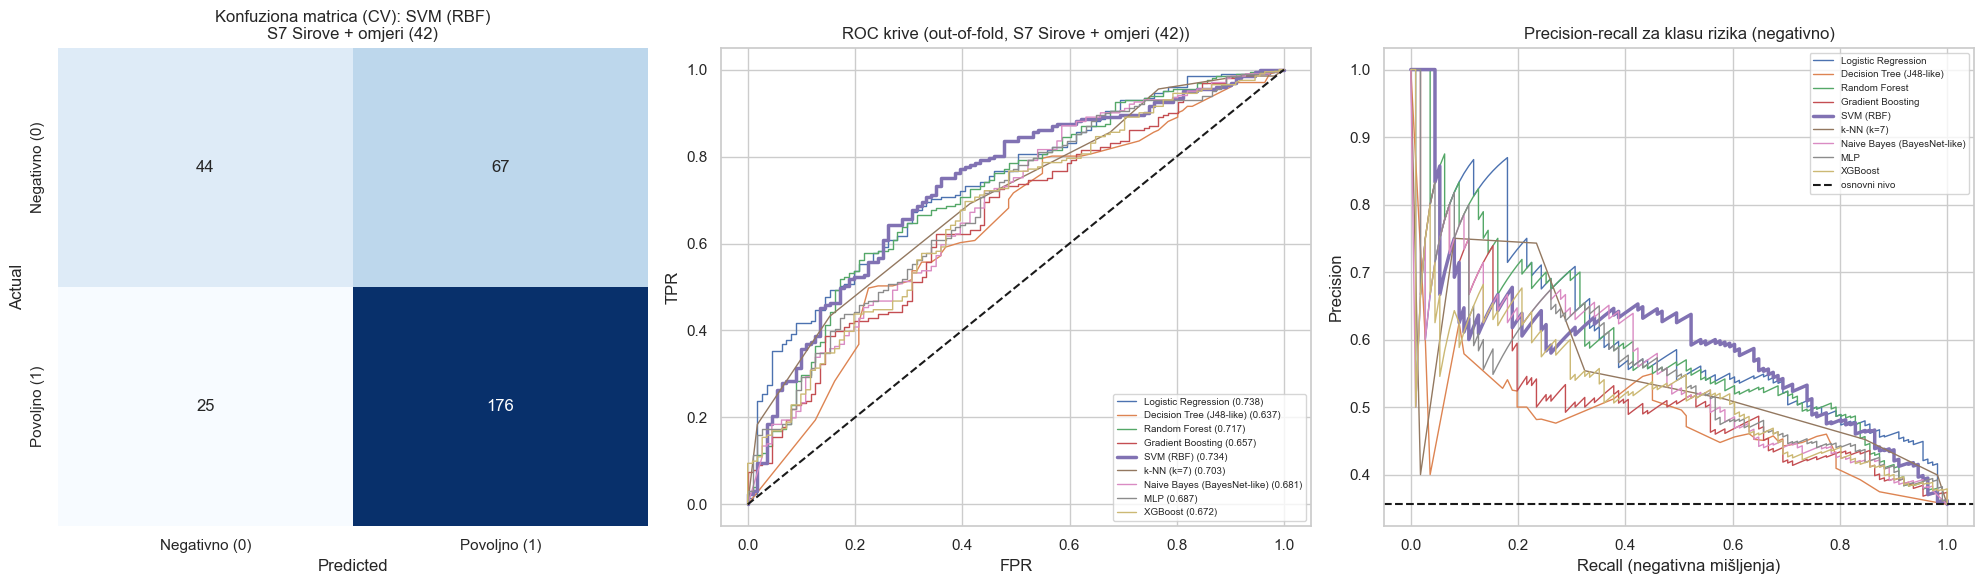

Normalizovana konfuziona matrica (po stvarnoj klasi):
               Negativno (0)  Povoljno (1)
Negativno (0)          0.396         0.604
Povoljno (1)           0.124         0.876


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

cm = confusion_matrix(y, pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
axes[0].set_title(f'Konfuziona matrica (CV): {best_model}\n{best_set}')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

for mname, p in OOF.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, lw=2.5 if mname == best_model else 1, label=f"{mname} ({roc_auc_score(y, p):.3f})")
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC krive (out-of-fold, ' + best_set + ')')
axes[1].legend(fontsize=7, loc='lower right')

for mname, p in OOF.items():
    prec, rec, _ = precision_recall_curve(1 - y, 1 - p)       # klasa rizika = negativno
    axes[2].plot(rec, prec, lw=2.5 if mname == best_model else 1, label=mname)
axes[2].axhline((1 - y).mean(), color='k', ls='--', label='osnovni nivo')
axes[2].set_xlabel('Recall (negativna mišljenja)'); axes[2].set_ylabel('Precision')
axes[2].set_title('Precision-recall za klasu rizika (negativno)')
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

print("Normalizovana konfuziona matrica (po stvarnoj klasi):")
print(pd.DataFrame(confusion_matrix(y, pred_best, normalize='true'), index=nazivi_klasa, columns=nazivi_klasa).round(3))

In [47]:
# Prag odlučivanja za klasu rizika: koliko preduzeća treba označiti da bismo uhvatili zadati dio negativnih mišljenja?
rizik_score = 1 - oof_best
y_rizik = 1 - y.values
prec, rec, thr = precision_recall_curve(y_rizik, rizik_score)
redovi_p = []
for cilj in [0.5, 0.6, 0.7, 0.8, 0.9]:
    idx = np.where(rec[:-1] >= cilj)[0]
    if len(idx):
        i = idx[-1]
        oznaceno = (rizik_score >= thr[i]).mean()
        redovi_p.append({'Ciljni recall': cilj, 'Prag rizika': thr[i], 'Postignuti recall': rec[i],
                         'Precision': prec[i], 'Označeno preduzeća (%)': oznaceno * 100})
print("Osnovni udio negativnih mišljenja: %.3f" % y_rizik.mean())
print(pd.DataFrame(redovi_p).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Osnovni udio negativnih mišljenja: 0.356
 Ciljni recall  Prag rizika  Postignuti recall  Precision  Označeno preduzeća (%)
         0.500        0.463              0.505      0.629                  28.526
         0.600        0.398              0.604      0.593                  36.218
         0.700        0.326              0.703      0.531                  47.115
         0.800        0.255              0.802      0.481                  59.295
         0.900        0.180              0.901      0.437                  73.397


In [48]:
# Cluster bootstrap po preduzećima (95% intervali povjerenja za out-of-fold metrike)
rng = np.random.default_rng(RS)
ids = groups.values
jedinstveni = np.unique(ids)
indeksi_po_id = {g: np.where(ids == g)[0] for g in jedinstveni}
yv = y.values
metr = {'ROC AUC': [], 'Accuracy': [], 'Recall (negativno)': [], 'Precision (negativno)': []}
for _ in range(1000):
    uzorak = rng.choice(jedinstveni, size=len(jedinstveni), replace=True)
    idx = np.concatenate([indeksi_po_id[g] for g in uzorak])
    if len(np.unique(yv[idx])) < 2:
        continue
    pb = (oof_best[idx] >= 0.5).astype(int)
    metr['ROC AUC'].append(roc_auc_score(yv[idx], oof_best[idx]))
    metr['Accuracy'].append(accuracy_score(yv[idx], pb))
    metr['Recall (negativno)'].append(recall_score(yv[idx], pb, pos_label=0, zero_division=0))
    metr['Precision (negativno)'].append(precision_score(yv[idx], pb, pos_label=0, zero_division=0))
ci = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in metr.items()},
                  index=['Prosjek', '2.5%', '97.5%']).T
print("95% interval povjerenja (cluster bootstrap po preduzećima, 1000 ponavljanja):")
print(ci.round(3))

95% interval povjerenja (cluster bootstrap po preduzećima, 1000 ponavljanja):
                       Prosjek  2.5%  97.5%
ROC AUC                  0.733 0.657  0.801
Accuracy                 0.705 0.644  0.766
Recall (negativno)       0.397 0.306  0.485
Precision (negativno)    0.637 0.514  0.758


## Four algorithms from the instructions (WEKA-like versions) - četiri algoritma iz uputa
Upute traže J48, IBk, MultilayerPerceptron i BayesNet. Ovdje su najbliži sklearn ekvivalenti:
- **J48 ≈** stablo s entropijom (C4.5 koristi gain ratio) i malim `min_samples_leaf = 2` uz rezidbu (`ccp_alpha`),
- **IBk ≈** k-NN s k = 1 (WEKA podrazumijevano) i k = 7,
- **MultilayerPerceptron ≈** jedan skriveni sloj od 12 neurona (WEKA: (atributi + klase)/2), SGD s brzinom učenja 0,3 i momentumom 0,2, kao u WEKA-i; uz to varijanta s Adam optimizatorom,
- **BayesNet ≈** diskretizacija (5 kvantilnih intervala) + `CategoricalNB`.

Ovo su aproksimacije; ako mentor traži tačne WEKA rezultate, koristite eksportovani `.arff` (ćelija na kraju).

In [49]:
def _u_int(a):
    return np.asarray(a).astype(int)

def weka_modeli():
    return {
        "J48-like (entropy, pruned)": pipe(DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2, ccp_alpha=0.01, random_state=RS)),
        "IBk (k=1)": pipe(KNeighborsClassifier(n_neighbors=1), scale=True),
        "IBk (k=7)": pipe(KNeighborsClassifier(n_neighbors=7), scale=True),
        "MLP (WEKA-like, SGD)": pipe(MLPClassifier(hidden_layer_sizes=(12,), solver='sgd', learning_rate_init=0.3, momentum=0.2,
                                                   max_iter=500, random_state=RS), scale=True),
        "MLP (Adam)": pipe(MLPClassifier(hidden_layer_sizes=(16,), alpha=0.01, max_iter=2000, random_state=RS), scale=True),
        "BayesNet-like (diskr. + CategoricalNB)": Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('disc', KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')),
            ('int', FunctionTransformer(_u_int)),
            ('m', CategoricalNB(min_categories=5, alpha=1.0))]),
    }

weka_rez10, weka_rezg = {}, {}
for naziv, model in weka_modeli().items():
    weka_rez10[naziv] = cv_scores(model, x, y, kind='kfold10')
    weka_rezg[naziv] = cv_scores(model, x, y, kind='group')

def tab_weka(rez):
    return pd.DataFrame({n: {k: v.mean() for k, v in d.items() if k in ['accuracy', 'f1', 'recall_neg', 'precision_neg', 'mcc', 'roc_auc']}
                         for n, d in rez.items()}).T.sort_values('roc_auc', ascending=False)
print("=== 10-fold stratifikovana CV (obavezno prema uputama; %d ponavljanja) ===" % N_REPEATS)
print(tab_weka(weka_rez10))
print("\n=== Grupna CV po preduzećima ===")
print(tab_weka(weka_rezg))
print("\nOsnovni nivo (uvijek 'povoljno'): accuracy =", round(y.mean(), 3))

=== 10-fold stratifikovana CV (obavezno prema uputama; 3 ponavljanja) ===
                                        roc_auc  accuracy    f1   mcc  recall_neg  precision_neg
MLP (WEKA-like, SGD)                      0.799     0.739 0.802 0.426       0.582          0.665
MLP (Adam)                                0.773     0.728 0.793 0.398       0.573          0.636
IBk (k=7)                                 0.717     0.702 0.783 0.322       0.458          0.617
BayesNet-like (diskr. + CategoricalNB)    0.636     0.604 0.671 0.172       0.534          0.453
J48-like (entropy, pruned)                0.619     0.630 0.707 0.205       0.498          0.488
IBk (k=1)                                 0.605     0.645 0.728 0.215       0.468          0.504

=== Grupna CV po preduzećima ===
                                        roc_auc  accuracy    f1   mcc  recall_neg  precision_neg
MLP (Adam)                                0.732     0.693 0.763 0.315       0.540          0.558
MLP (WEKA-like, SGD

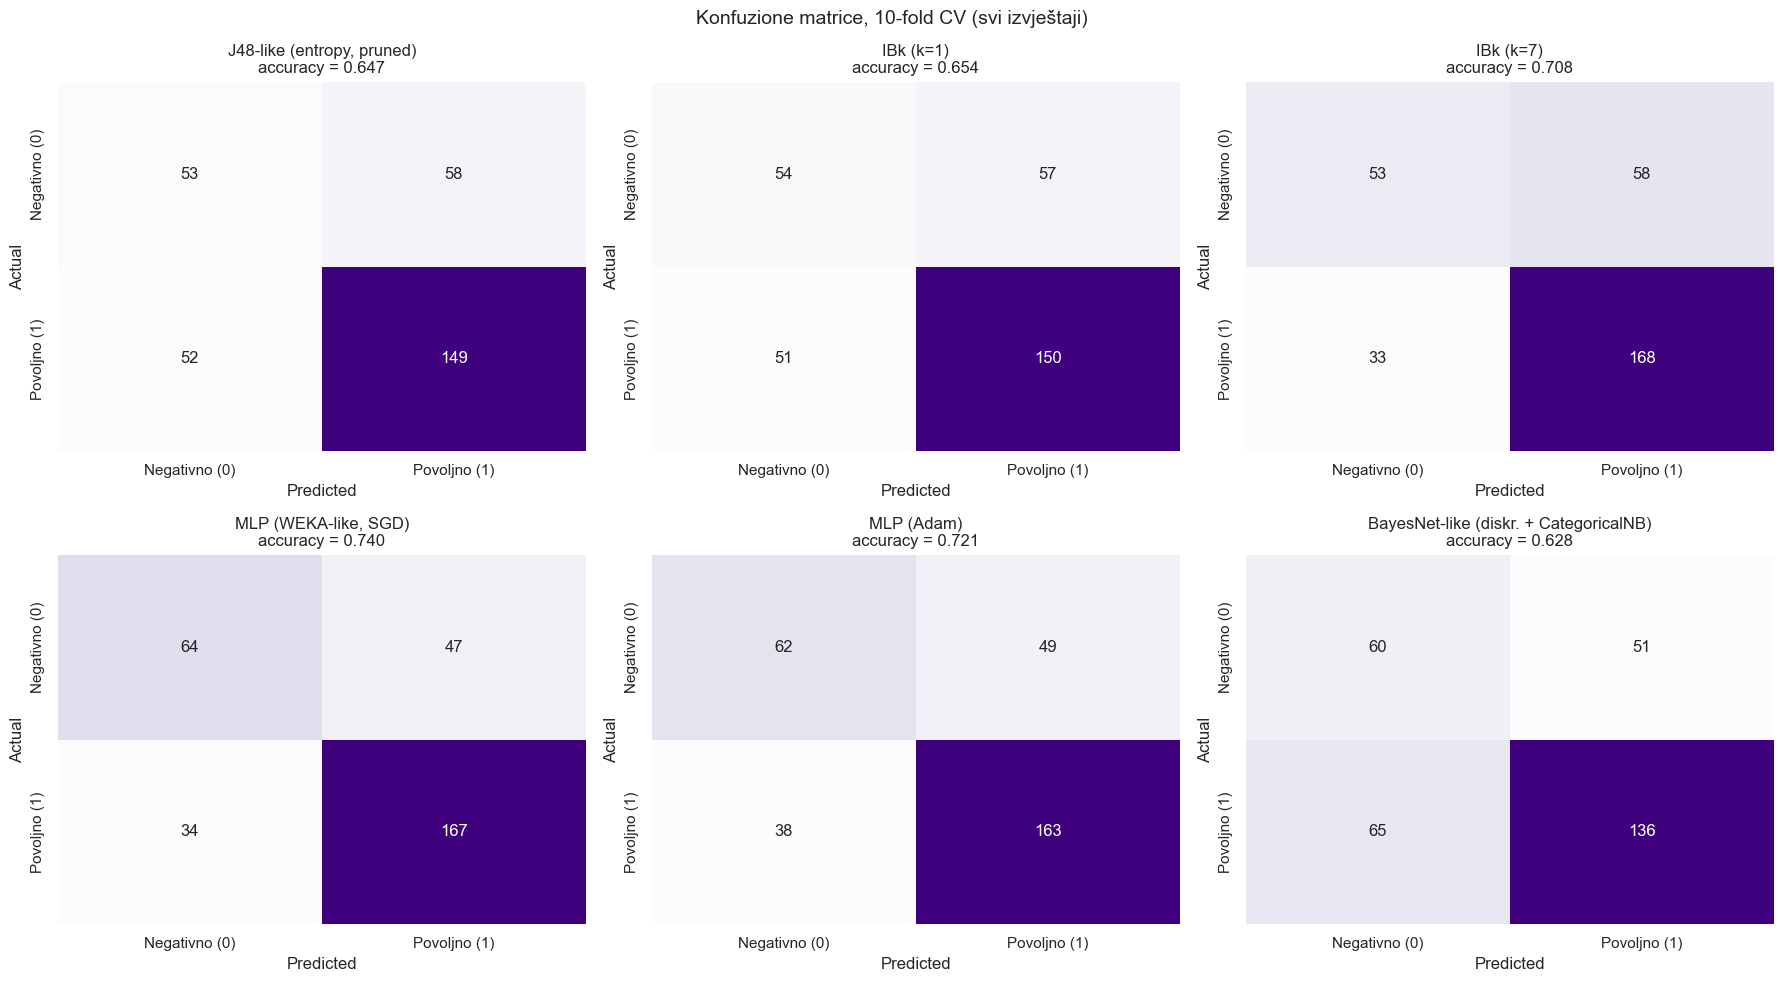

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, (naziv, model) in enumerate(weka_modeli().items()):
    pr = cross_val_predict(model, x, y, cv=StratifiedKFold(10, shuffle=True, random_state=0))
    cm = confusion_matrix(y, pr)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[i],
                xticklabels=nazivi_klasa, yticklabels=nazivi_klasa)
    axes[i].set_title(f"{naziv}\naccuracy = {accuracy_score(y, pr):.3f}")
    axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('Actual')
plt.suptitle('Konfuzione matrice, 10-fold CV (svi izvještaji)', fontsize=14)
plt.tight_layout()
plt.show()

## Sensitivity to class definition - analiza osjetljivosti na definiciju klase
Upute dopuštaju „pozitivno vs ostalo“ uz eksplicitno navođenje, a izvorne klase su četiri. Ovdje provjeravamo koliko rezultat zavisi od izbora:
- **A)** pozitivno (37) vs ostalo (275); osnovni nivo je 88%, pa su važni AUC, PR-AUC, MCC i balanced accuracy, ne accuracy.
- **B)** troklasno: pozitivno (37) / s rezervom (164) / negativno ili suzdržavanje (111); osnovni nivo je 52,6%, glavna metrika macro-F1.

In [51]:
from sklearn.metrics import average_precision_score
y_pos = (df['misljenje'] == 'Pozitivno mišljenje').astype(int)
y3 = df['cilj_3klase'].astype(int)
print("A) pozitivno vs ostalo:", y_pos.value_counts().to_dict(), "| osnovni nivo accuracy =", round(1 - y_pos.mean(), 3))
print("B) troklasno:", y3.value_counts().sort_index().to_dict(), "| osnovni nivo accuracy =", round(y3.value_counts(normalize=True).max(), 3))

sens_modeli = {k: v for k, v in napravi_modele().items()
               if k in ['Logistic Regression', 'Random Forest', 'SVM (RBF)', 'MLP', 'Gradient Boosting']}
scoring_A = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'balanced_accuracy': 'balanced_accuracy',
             'f1_pozitivno': 'f1', 'mcc': make_scorer(matthews_corrcoef)}
scoring_B = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'balanced_accuracy': 'balanced_accuracy',
             'roc_auc_ovr': 'roc_auc_ovr'}
sensA = {m: cv_scores(mod, x, y_pos, kind='group', scoring=scoring_A) for m, mod in sens_modeli.items()}
sensB = {m: cv_scores(mod, x, y3, kind='group', scoring=scoring_B) for m, mod in sens_modeli.items()}
pd.options.display.float_format = '{:,.3f}'.format
print("\n=== A) pozitivno vs ostalo (grupna CV) ===")
print(pd.DataFrame({m: {k: v.mean() for k, v in d.items()} for m, d in sensA.items()}).T.sort_values('roc_auc', ascending=False))
print("\n=== B) troklasno (grupna CV) ===")
print(pd.DataFrame({m: {k: v.mean() for k, v in d.items()} for m, d in sensB.items()}).T.sort_values('f1_macro', ascending=False))

A) pozitivno vs ostalo: {0: 275, 1: 37} | osnovni nivo accuracy = 0.881
B) troklasno: {0: 37, 1: 164, 2: 111} | osnovni nivo accuracy = 0.526

=== A) pozitivno vs ostalo (grupna CV) ===
                     roc_auc  pr_auc  balanced_accuracy  f1_pozitivno   mcc
Logistic Regression    0.903   0.575              0.855         0.550 0.522
MLP                    0.888   0.560              0.679         0.459 0.414
SVM (RBF)              0.877   0.532              0.810         0.474 0.434
Gradient Boosting      0.785   0.439              0.598         0.279 0.305
Random Forest          0.777   0.417              0.556         0.185 0.169

=== B) troklasno (grupna CV) ===
                     accuracy  f1_macro  balanced_accuracy  roc_auc_ovr
MLP                     0.620     0.567              0.580        0.789
Logistic Regression     0.540     0.532              0.628        0.766
SVM (RBF)               0.494     0.483              0.603        0.752
Random Forest           0.563     0.

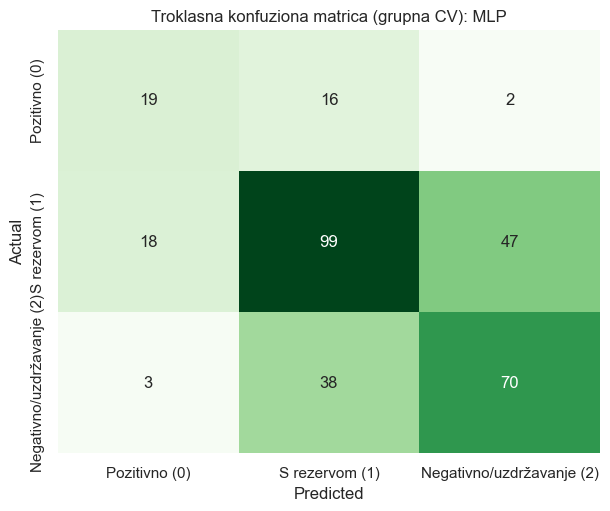

                           precision    recall  f1-score   support

            Pozitivno (0)      0.475     0.514     0.494        37
           S rezervom (1)      0.647     0.604     0.625       164
Negativno/uzdržavanje (2)      0.588     0.631     0.609       111

                 accuracy                          0.603       312
                macro avg      0.570     0.583     0.576       312
             weighted avg      0.606     0.603     0.603       312



In [52]:
# Konfuziona matrica 3x3 za najbolji model po macro-F1
tabB = pd.DataFrame({m: {k: v.mean() for k, v in d.items()} for m, d in sensB.items()}).T
najbolji_B = tabB['f1_macro'].idxmax()
pr3 = cross_val_predict(sens_modeli[najbolji_B], x, y3, cv=StratifiedGroupKFold(5, shuffle=True, random_state=1), groups=groups)
imena3 = ['Pozitivno (0)', 'S rezervom (1)', 'Negativno/uzdržavanje (2)']
plt.figure(figsize=(7, 5.5))
sns.heatmap(confusion_matrix(y3, pr3), annot=True, fmt='d', cmap='Greens', cbar=False, xticklabels=imena3, yticklabels=imena3)
plt.title(f'Troklasna konfuziona matrica (grupna CV): {najbolji_B}')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()
print(classification_report(y3, pr3, target_names=imena3, digits=3))

Ako je rezultat za A) i B) znatno slabiji nego za binarnu klasu, to je očekivano: klasa „pozitivno“ je rijetka (12%), a „s rezervom“ je granična klasa koju je teško razlikovati od oba susjeda. Zato je binarna definicija (uz obrazloženje) razuman primarni izbor.

## Rolling temporal validation - klizna vremenska validacija
Za svaku godinu Y od 2014 model se trenira na izvještajima iz godina prije Y, a testira na godini Y (realna situacija: model nikad ne vidi budućnost). Rezultati se objedinjuju preko godina. Ovo je nezavisna provjera izbora najboljeg modela i procjena za praktičnu primjenu (rangiranje preduzeća unutar godine).

In [53]:
godine_sve = sorted(df['Godina_izvjestaja'].unique())
test_godine = [g for g in godine_sve if g >= 2014]
roll = {m: {'y': [], 'p': [], 'god': []} for m in modeli_za_skup(best_set)}
for g in test_godine:
    tr = (df['Godina_izvjestaja'] < g).values
    te = (df['Godina_izvjestaja'] == g).values
    if te.sum() < 5 or len(np.unique(y[tr])) < 2:
        continue
    for m, model in modeli_za_skup(best_set).items():
        mdl = clone(model).fit(X_best[tr], y[tr])
        roll[m]['p'].extend(mdl.predict_proba(X_best[te])[:, 1])
        roll[m]['y'].extend(y[te])
        roll[m]['god'].extend([g] * te.sum())

redovi_r = []
for m, d in roll.items():
    yt, pt = np.array(d['y']), np.array(d['p'])
    pr = (pt >= 0.5).astype(int)
    redovi_r.append({'Model': m, 'ROC AUC': roc_auc_score(yt, pt), 'Accuracy': accuracy_score(yt, pr),
                     'Recall (negativno)': recall_score(yt, pr, pos_label=0), 'Precision (negativno)': precision_score(yt, pr, pos_label=0, zero_division=0),
                     'MCC': matthews_corrcoef(yt, pr)})
roll_tab = pd.DataFrame(redovi_r).set_index('Model').sort_values('ROC AUC', ascending=False)
print(f"Klizna validacija (skup atributa: {best_set}), testne godine {test_godine[0]}-{test_godine[-1]}, ukupno {len(next(iter(roll.values()))['y'])} izvještaja")
print("Osnovni nivo (uvijek 'povoljno'): accuracy =", round(np.mean(next(iter(roll.values()))['y']), 3))
print(roll_tab)

Klizna validacija (skup atributa: S7 Sirove + omjeri (42)), testne godine 2014-2025, ukupno 221 izvještaja
Osnovni nivo (uvijek 'povoljno'): accuracy = 0.647
                             ROC AUC  Accuracy  Recall (negativno)  Precision (negativno)   MCC
Model                                                                                          
SVM (RBF)                      0.717     0.674               0.474                  0.544 0.267
Random Forest                  0.702     0.679               0.474                  0.552 0.275
Logistic Regression            0.702     0.647               0.641                  0.500 0.280
MLP                            0.701     0.638               0.577                  0.489 0.241
k-NN (k=7)                     0.682     0.688               0.359                  0.596 0.264
Gradient Boosting              0.667     0.652               0.462                  0.507 0.222
XGBoost                        0.636     0.652               0.449        

=== SVM (RBF): rezultati po godinama (top 30% preduzeća svake godine po riziku) ===
 Godina  n  Udio negativnih   AUC  k (top 30%)  Negativnih u top-k  Lift
   2014 10            0.300 0.286            3               0.000 0.000
   2015  8            0.250 0.667            2               0.500 2.000
   2016 15            0.667 0.660            4               1.000 1.500
   2017 19            0.316 0.679            6               0.667 2.111
   2018 24            0.542 0.804            7               0.857 1.582
   2019 33            0.182 0.877           10               0.400 2.200
   2020 19            0.316 0.449            6               0.333 1.056
   2021 21            0.381 0.558            6               0.500 1.312
   2022 18            0.167 0.867            5               0.400 2.400
   2023 25            0.440 0.786            8               0.875 1.989
   2024 17            0.235 0.558            5               0.400 1.700
   2025 12            0.500 0.722       

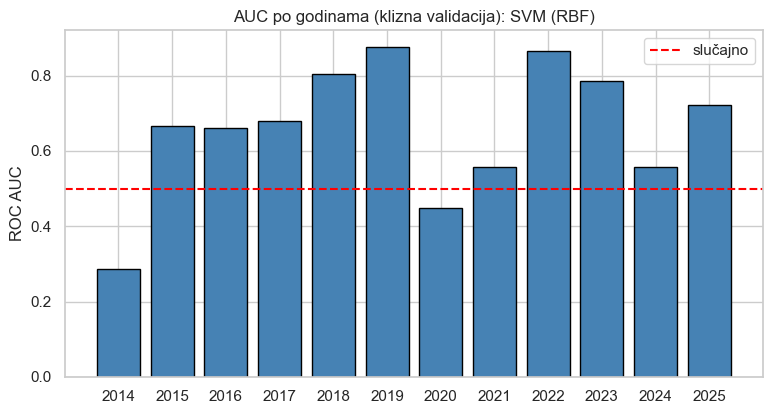

In [54]:
d = roll[best_model]
rd = pd.DataFrame({'god': d['god'], 'y': d['y'], 'p': d['p']})
redovi_g = []
for g, gr in rd.groupby('god'):
    rizik = 1 - gr['p'].values
    neg = 1 - gr['y'].values
    k = max(1, int(round(0.3 * len(gr))))                      # top 30% preduzeća te godine
    idx = np.argsort(-rizik)[:k]
    osn = neg.mean()
    redovi_g.append({'Godina': int(g), 'n': len(gr), 'Udio negativnih': osn,
                     'AUC': roc_auc_score(gr['y'], gr['p']) if gr['y'].nunique() > 1 else np.nan,
                     'k (top 30%)': k, 'Negativnih u top-k': neg[idx].mean(), 'Lift': neg[idx].mean() / osn if osn > 0 else np.nan})
roll_god = pd.DataFrame(redovi_g)
print(f"=== {best_model}: rezultati po godinama (top 30% preduzeća svake godine po riziku) ===")
print(roll_god.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
pogodak = np.average(roll_god['Negativnih u top-k'], weights=roll_god['k (top 30%)'])
osn_p = np.average(roll_god['Udio negativnih'], weights=roll_god['n'])
print(f"\nObjedinjeno: negativnih u top 30%: {pogodak:.3f} naspram osnovnog {osn_p:.3f} (lift = {pogodak / osn_p:.2f})")

plt.figure(figsize=(9, 4.5))
plt.bar(roll_god['Godina'].astype(str), roll_god['AUC'], color='steelblue', edgecolor='black')
plt.axhline(0.5, color='red', ls='--', label='slučajno')
plt.ylabel('ROC AUC'); plt.title(f'AUC po godinama (klizna validacija): {best_model}')
plt.legend(); plt.show()

## Feature importance - važnost značajki

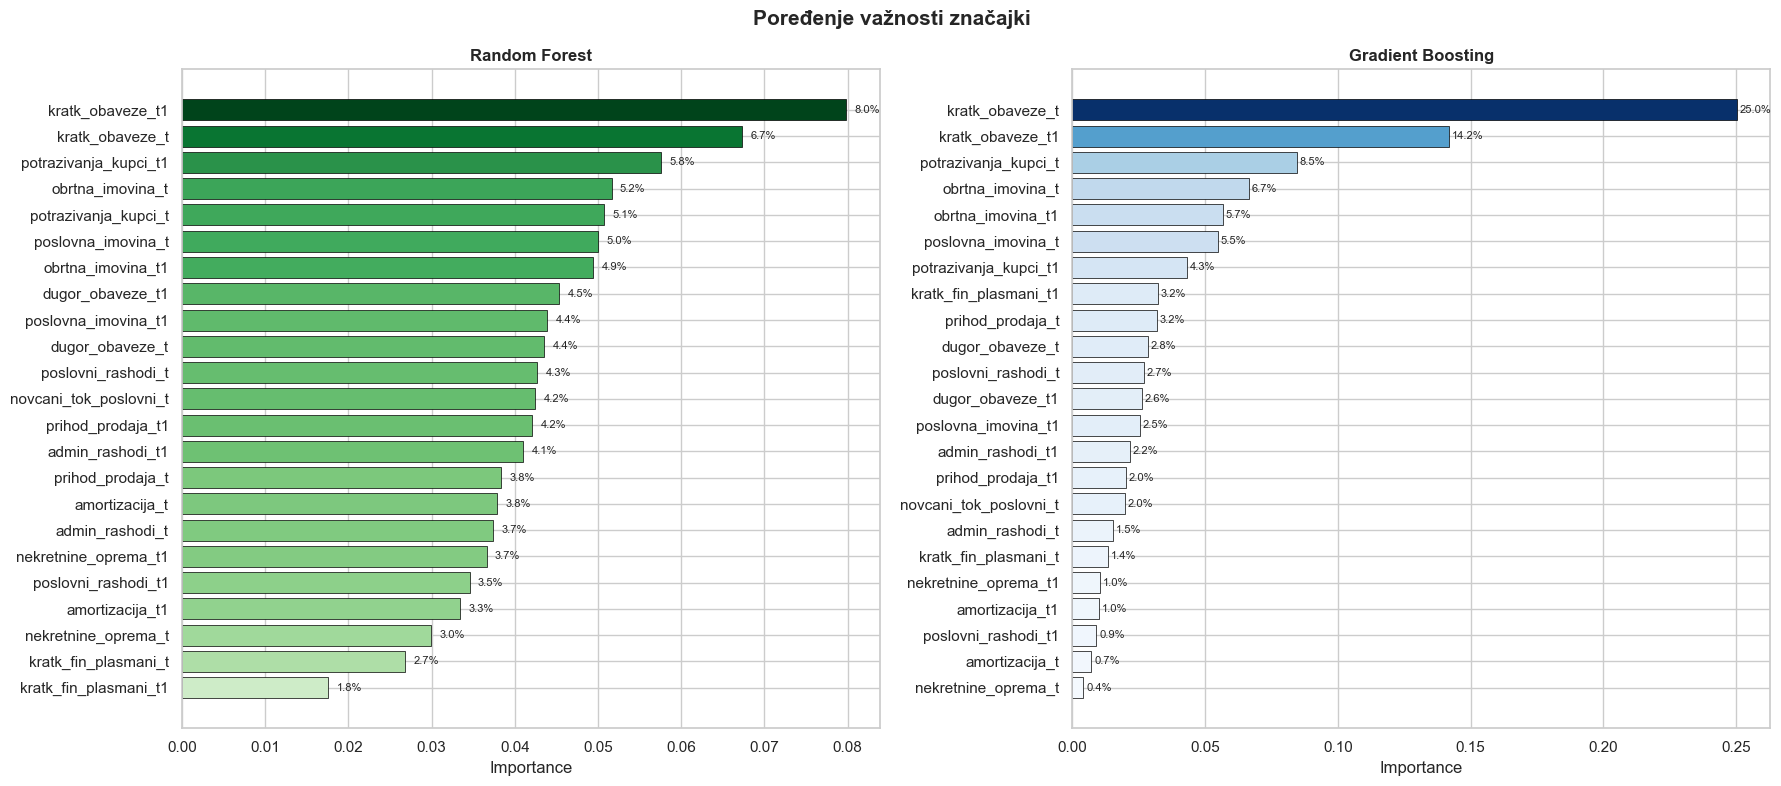

                  Feature  Importance  Importance_Pct
20       kratk_obaveze_t1       0.080           7.984
18        kratk_obaveze_t       0.067           6.731
2   potrazivanja_kupci_t1       0.058           5.754
6        obrtna_imovina_t       0.052           5.163
0    potrazivanja_kupci_t       0.051           5.073
9      poslovna_imovina_t       0.050           4.998
10      obrtna_imovina_t1       0.049           4.940
21       dugor_obaveze_t1       0.045           4.535


In [55]:
rf_model = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS))
rf_model.fit(x, y)
fi_rf = pd.DataFrame({'Feature': numericke, 'Importance': rf_model.named_steps['m'].feature_importances_}).sort_values('Importance', ascending=False)
fi_rf['Importance_Pct'] = fi_rf['Importance'] * 100

gb_model = pipe(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RS))
gb_model.fit(x, y)
fi_gb = pd.DataFrame({'Feature': numericke, 'Importance': gb_model.named_steps['m'].feature_importances_}).sort_values('Importance', ascending=False)
fi_gb['Importance_Pct'] = fi_gb['Importance'] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
for ax, fi, cmap, naslov in [(ax1, fi_rf, plt.cm.Greens, 'Random Forest'), (ax2, fi_gb, plt.cm.Blues, 'Gradient Boosting')]:
    boje = cmap(fi['Importance'] / fi['Importance'].max())
    bars = ax.barh(fi['Feature'], fi['Importance'], color=boje, edgecolor='black', linewidth=0.5)
    for b, imp, pct in zip(bars, fi['Importance'], fi['Importance_Pct']):
        ax.text(b.get_width() + 0.001, b.get_y() + b.get_height() / 2, f'{pct:.1f}%', va='center', fontsize=8)
    ax.invert_yaxis(); ax.set_title(naslov, fontweight='bold'); ax.set_xlabel('Importance')
plt.suptitle('Poređenje važnosti značajki', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
print(fi_rf.head(8).round(4))

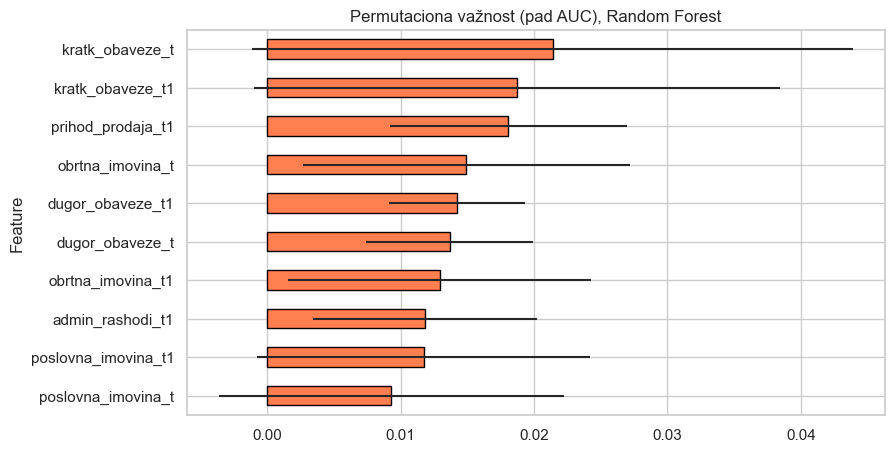

In [56]:
# Permutaciona važnost (pouzdanija od impurity importance) na test skupu
from sklearn.inspection import permutation_importance
rf_p = pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', random_state=RS)).fit(x_train, y_train)
pi = permutation_importance(rf_p, x_test, y_test, scoring='roc_auc', n_repeats=30, random_state=RS)
pi_df = pd.DataFrame({'Feature': numericke, 'mean': pi.importances_mean, 'std': pi.importances_std}).sort_values('mean', ascending=False)
pi_df.head(10).iloc[::-1].plot(x='Feature', y='mean', xerr='std', kind='barh', legend=False, figsize=(9, 5), color='coral', edgecolor='black')
plt.title('Permutaciona važnost (pad AUC), Random Forest')
plt.show()

## Decision tree visualisation - vizualizacija stabla odlučivanja
Plitko stablo daje pravila čitljiva revizorima (analogno J48/REPTree iz rada).

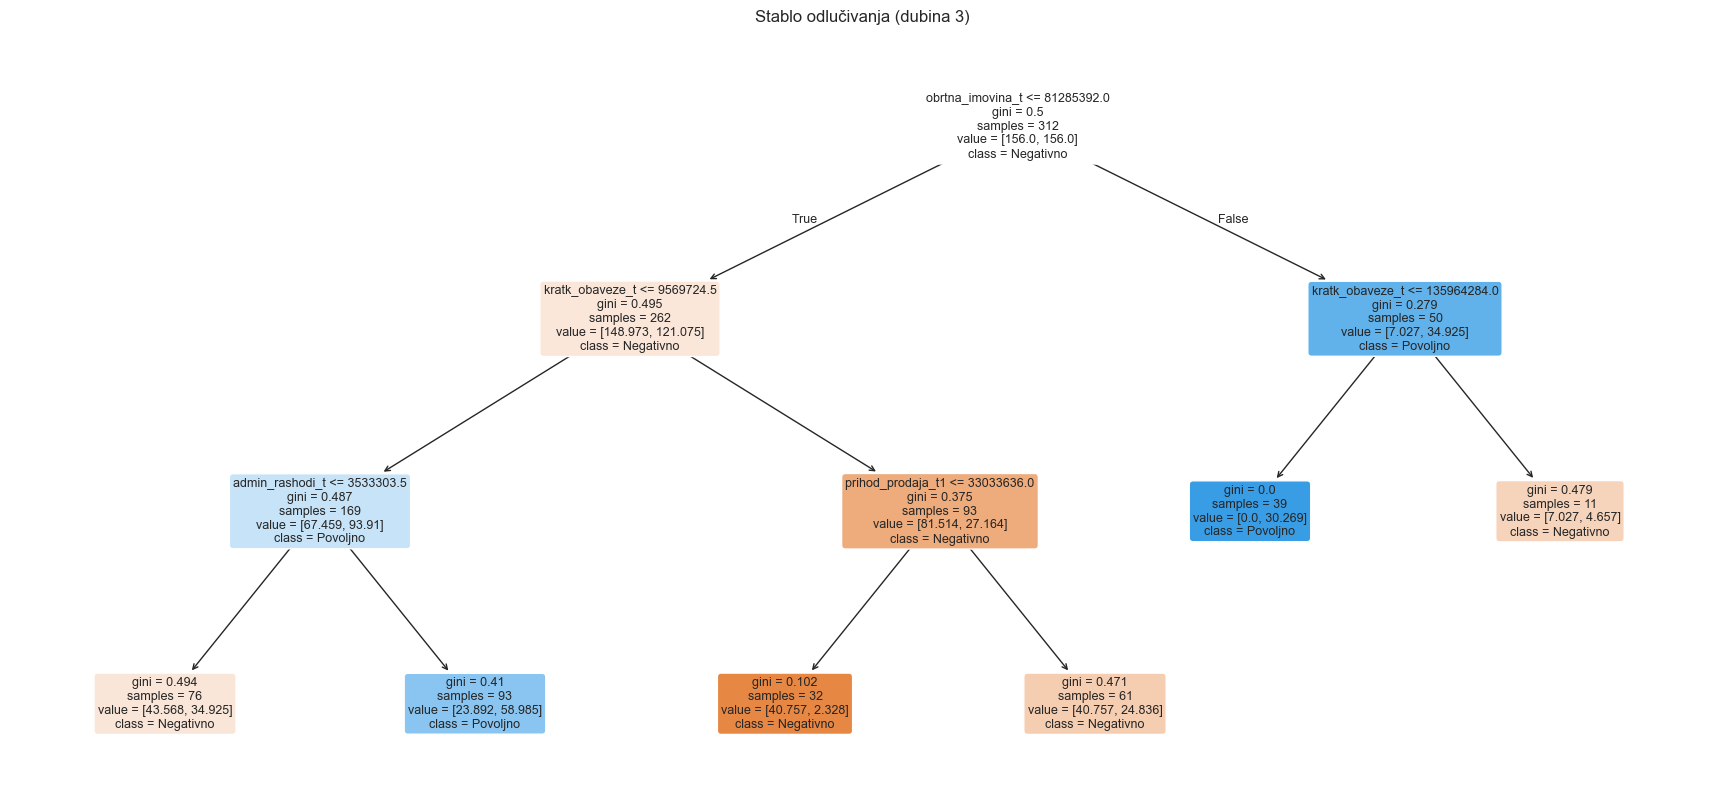

In [57]:
stablo = DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, class_weight='balanced', random_state=RS)
stablo.fit(SimpleImputer(strategy='median').fit_transform(x), y)
plt.figure(figsize=(22, 10))
plot_tree(stablo, feature_names=numericke, class_names=['Negativno', 'Povoljno'], filled=True, rounded=True, fontsize=9)
plt.title('Stablo odlučivanja (dubina 3)')
plt.show()

## Risk ranking - rangiranje preduzeća po riziku (praktična primjena)
Revizori biraju samo 10-15 preduzeća godišnje. Mjerimo koliko se negativnih mišljenja nalazi među top-k preduzećima rangiranim po vjerovatnoći negativnog mišljenja, koristeći *out-of-fold* predikcije izabranog modela (grupna CV).

Model: SVM (RBF) | skup atributa: S7 Sirove + omjeri (42)
Osnovni udio negativnih mišljenja: 0.356
   top-k  udio negativnih u top-k  lift
0     10                    0.700 1.970
1     15                    0.667 1.870
2     20                    0.600 1.690
3     30                    0.667 1.870
4     50                    0.580 1.630
5    100                    0.600 1.690


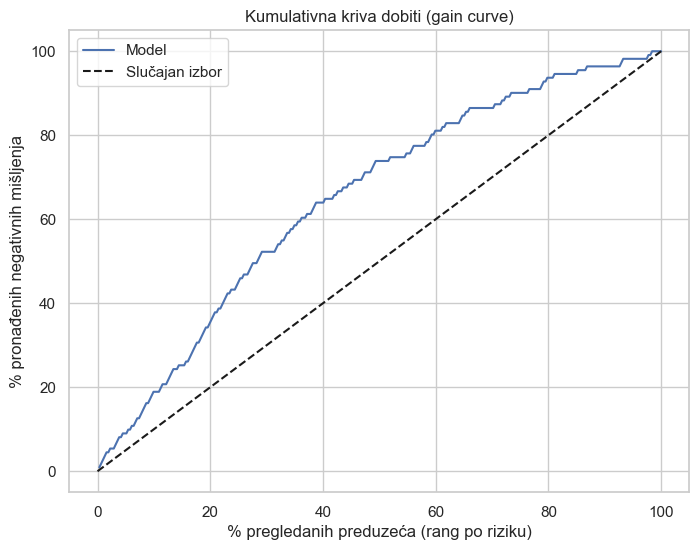

In [58]:
rizik = 1 - oof_best                  # vjerovatnoća negativnog mišljenja
rang = pd.DataFrame({'rizik': rizik, 'negativno': 1 - y.values}).sort_values('rizik', ascending=False).reset_index(drop=True)

osnovni = rang['negativno'].mean()
tab_lift = []
for k in [10, 15, 20, 30, 50, 100]:
    pr = rang['negativno'].head(k).mean()
    tab_lift.append({'top-k': k, 'udio negativnih u top-k': round(pr, 3), 'lift': round(pr / osnovni, 2)})
print(f"Model: {best_model} | skup atributa: {best_set}")
print("Osnovni udio negativnih mišljenja:", round(osnovni, 3))
lift_tab = pd.DataFrame(tab_lift)
print(lift_tab)

kum = rang['negativno'].cumsum() / rang['negativno'].sum()
plt.figure(figsize=(8, 6))
plt.plot(np.arange(1, len(rang) + 1) / len(rang) * 100, kum * 100, label='Model')
plt.plot([0, 100], [0, 100], 'k--', label='Slučajan izbor')
plt.xlabel('% pregledanih preduzeća (rang po riziku)')
plt.ylabel('% pronađenih negativnih mišljenja')
plt.title('Kumulativna kriva dobiti (gain curve)')
plt.legend(); plt.show()

## Export for WEKA - eksport u .arff
Upute traže eksport u .arff/.csv. CSV već postoji; ovdje se pravi `.arff` sa 23 ulazna atributa i klasom (`Negativno`/`Povoljno`) za ponavljanje četiri algoritma u WEKA-i. Fajl sadrži podatke, pa ga ne objavljivati javno (nalazi se u `.gitignore`).

In [59]:
import os
EXPORT_ARFF = True
def export_arff(d, kolone, cilj, putanja, relacija='revizija'):
    os.makedirs(os.path.dirname(putanja) or '.', exist_ok=True)
    with open(putanja, 'w', encoding='utf-8') as f:
        f.write(f"@relation {relacija}\n\n")
        for c in kolone:
            f.write(f"@attribute {c} numeric\n")
        f.write("@attribute klasa {Negativno,Povoljno}\n\n@data\n")
        for _, red in d.iterrows():
            vrijednosti = ['?' if pd.isna(red[c]) else format(float(red[c]), '.10g') for c in kolone]
            f.write(','.join(vrijednosti) + ',' + ('Povoljno' if red[cilj] == 1 else 'Negativno') + '\n')
    print("Sačuvano:", putanja, "| redova:", len(d), "| atributa:", len(kolone))

if EXPORT_ARFF:
    export_arff(df, numericke, 'cilj_binarno', 'data/dataset_revizija.arff')

Sačuvano: data/dataset_revizija.arff | redova: 312 | atributa: 23


## Conclusion - zaključak
Sažetak ispod se **generiše iz izračunatih rezultata** (nema ručno unesenih brojeva), pa uvijek odgovara tabelama iznad.

In [60]:
from IPython.display import display, Markdown

osn_acc = y.mean()
dummy_acc = REZ_dummy['accuracy'].mean()
sc = REZ[(best_set, best_model)]
n_znac_alg = int((friedman_algoritmi['p'] < 0.05).sum())
n_znac_skup = int((friedman_skupovi['p'] < 0.05).sum())
prosjek_skup = pivot_auc.mean(axis=1)
prosjek_alg = pivot_auc.mean(axis=0)
s1 = skupovi_nazivi[0]

h1_ok = (p_h1_acc < 0.05) and (p_h1_auc < 0.05)
h2_alg = friedman_algoritmi.loc[friedman_algoritmi['Skup'] == s1, 'p'].iloc[0] < 0.05
h2_skup = p_friedman_skupovi_prosjek < 0.05
n_sig_sets = int((tab_q['p (Holm)'] < 0.05).sum())
n_sig_alg = int((tab_p['p (Holm)'] < 0.05).sum())

lift15 = lift_tab.loc[lift_tab['top-k'] == 15, 'udio negativnih u top-k'].iloc[0]
tekst = f"""
**Podaci:** {len(df)} izvještaja, {len(numericke)} ulaznih pozicija, {groups.nunique()} (aproksimativno) različitih preduzeća; ciljna klasa: {int(y.sum())} povoljnih / {int((1-y).sum())} negativnih (osnovni nivo accuracy = {osn_acc:.3f}).

**Najbolja kombinacija (grupna CV, po AUC):** {best_set} + {best_model}: AUC = {sc['roc_auc'].mean():.3f}, accuracy = {sc['accuracy'].mean():.3f} (osnovni nivo {dummy_acc:.3f}), MCC = {sc['mcc'].mean():.3f}, recall za negativno = {sc['recall_neg'].mean():.3f}, precision za negativno = {sc['precision_neg'].mean():.3f}.

**H1** (moguće je klasifikovati uz zadovoljavajuću tačnost): jednostrani korigovani t-test naspram osnovnog nivoa daje p = {p_h1_acc:.4f} za accuracy i p = {p_h1_auc:.4f} za AUC, pa H1 je {'**podržana**' if h1_ok else '**samo djelimično podržana** (barem jedan test nije značajan)'}. Praktično, riječ je o {'umjerenoj' if sc['roc_auc'].mean() < 0.8 else 'dobroj'} prediktivnoj moći (AUC ≈ {sc['roc_auc'].mean():.2f}).

**H2** (rezultat zavisi od algoritma i skupa atributa): Friedmanov test među algoritmima je značajan na {n_znac_alg} od {len(friedman_algoritmi)} skupova atributa (na S1: {'značajan' if h2_alg else 'nije značajan'}); među skupovima atributa značajan je za {n_znac_skup} od {len(friedman_skupovi)} algoritama (usrednjeno preko algoritama: p = {p_friedman_skupovi_prosjek:.4f}, {'značajan' if h2_skup else 'nije značajan'}). Nakon Holmove korekcije značajno različitih uparenih poređenja: {n_sig_alg} među algoritmima i {n_sig_sets} među skupovima atributa (naspram S1).

**Skupovi atributa (prosječni AUC):** najbolji {prosjek_skup.idxmax()} ({prosjek_skup.max():.3f}), najslabiji {prosjek_skup.idxmin()} ({prosjek_skup.min():.3f}). **Algoritmi (prosječni AUC):** najbolji {prosjek_alg.idxmax()} ({prosjek_alg.max():.3f}), najslabiji {prosjek_alg.idxmin()} ({prosjek_alg.min():.3f}).

**Klizna vremenska validacija ({best_model}):** objedinjeni AUC = {roll_tab.loc[best_model, 'ROC AUC']:.3f}, accuracy = {roll_tab.loc[best_model, 'Accuracy']:.3f}; među top 30% preduzeća svake godine {pogodak:.0%} ima negativno mišljenje (osnovno {osn_p:.0%}, lift {pogodak / osn_p:.2f}).

**Rangiranje rizika (out-of-fold):** među 15 preduzeća s najvećim rizikom {lift15:.0%} ima negativno mišljenje (osnovni udio {osnovni:.0%}).
"""
display(Markdown(tekst))


**Podaci:** 312 izvještaja, 23 ulaznih pozicija, 170 (aproksimativno) različitih preduzeća; ciljna klasa: 201 povoljnih / 111 negativnih (osnovni nivo accuracy = 0.644).

**Najbolja kombinacija (grupna CV, po AUC):** S7 Sirove + omjeri (42) + SVM (RBF): AUC = 0.736, accuracy = 0.711 (osnovni nivo 0.650), MCC = 0.378, recall za negativno = 0.667, precision za negativno = 0.557.

**H1** (moguće je klasifikovati uz zadovoljavajuću tačnost): jednostrani korigovani t-test naspram osnovnog nivoa daje p = 0.1720 za accuracy i p = 0.0003 za AUC, pa H1 je **samo djelimično podržana** (barem jedan test nije značajan). Praktično, riječ je o umjerenoj prediktivnoj moći (AUC ≈ 0.74).

**H2** (rezultat zavisi od algoritma i skupa atributa): Friedmanov test među algoritmima je značajan na 7 od 7 skupova atributa (na S1: značajan); među skupovima atributa značajan je za 8 od 9 algoritama (usrednjeno preko algoritama: p = 0.0000, značajan). Nakon Holmove korekcije značajno različitih uparenih poređenja: 0 među algoritmima i 0 među skupovima atributa (naspram S1).

**Skupovi atributa (prosječni AUC):** najbolji S7 Sirove + omjeri (42) (0.699), najslabiji S5 CFS (0.591). **Algoritmi (prosječni AUC):** najbolji SVM (RBF) (0.682), najslabiji Decision Tree (J48-like) (0.583).

**Klizna vremenska validacija (SVM (RBF)):** objedinjeni AUC = 0.717, accuracy = 0.674; među top 30% preduzeća svake godine 59% ima negativno mišljenje (osnovno 35%, lift 1.67).

**Rangiranje rizika (out-of-fold):** među 15 preduzeća s najvećim rizikom 67% ima negativno mišljenje (osnovni udio 36%).


### Interpretacija i ograničenja
- Bilansne pozicije nose **umjeren** signal o mišljenju revizora; model je upotrebljiv kao pomoć pri rangiranju preduzeća za plan revizije (risk-based planiranje), ne kao zamjena za revizorsku odluku.
- Rezultati iz jedne slučajne podjele 80/20 su ilustrativni (test ima samo 63 primjera i ista preduzeća mogu biti u treningu i testu); za zaključke koristiti CV (10-fold, grupna) i vremensku validaciju.
- Izbor najbolje kombinacije među mnogo kandidata blago precjenjuje performanse (winner's curse); klizna vremenska validacija i intervali povjerenja daju realniju sliku.
- ID preduzeća i sektor određeni su automatski iz naziva i treba ih ručno provjeriti; mišljenje je proxy za tačnost izvještaja, a ne dokaz prevare.
- sklearn modeli su aproksimacije WEKA algoritama (J48, IBk, MLP, BayesNet); za tačno poređenje s radom koristiti eksportovani `.arff`.